# Laboratorio 7: NLP end-to-end y Embeddings

CC3092 Deep Learning y Sistemas Inteligentes, Universidad del Valle de Guatemala

Fabián Morales

En este notebook se construye un pipeline completo de procesamiento de lenguaje natural: texto crudo, tokens, IDs, vectores, modelo y salida. Se entrenan embeddings skip-gram con negative sampling desde cero en PyTorch sobre WikiText-103, se validan contra Word2Vec de gensim y se comparan con GloVe preentrenado en analogías, similitud de palabras y clasificación de noticias de AG News.

## 0. Configuración del entorno

Se fijan las semillas, se detecta el hardware y se crean las carpetas para figuras, resultados, modelos y datos intermedios.

In [1]:
import os, re, time, json, html, random, platform, subprocess
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.word2vec import LineSentence
from gensim.models.callbacks import CallbackAny2Vec
from gensim.test.utils import datapath
import nltk
import spacy
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

fijar_semilla()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for carpeta in ["figuras", "resultados", "modelos", "datos"]:
    os.makedirs(carpeta, exist_ok=True)

def nombre_cpu():
    try:
        salida = subprocess.check_output(
            ["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"], text=True)
        return salida.strip()
    except Exception:
        return platform.processor()

HARDWARE = {
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU",
    "memoria_gpu_gb": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1) if torch.cuda.is_available() else 0,
    "cpu": nombre_cpu(),
    "nucleos": os.cpu_count(),
    "sistema": platform.platform(),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "gensim": gensim.__version__,
}
for k, v in HARDWARE.items():
    print(f"{k:15s}: {v}")

gpu            : NVIDIA GeForce RTX 5070 Ti
memoria_gpu_gb : 15.9
cpu            : AMD Ryzen 7 7800X3D 8-Core Processor
nucleos        : 16
sistema        : Windows-11-10.0.26200-SP0
python         : 3.12.14
torch          : 2.14.1+cu130
gensim         : 4.4.0


In [2]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "lines.linewidth": 2,
})
COLOR = {"sgns": "#2a78d6", "gensim": "#eb6834", "glove": "#1baf7a", "aleatoria": "#8a8984", "tfidf": "#9b5de5"}
NOMBRE = {"sgns": "SGNS propio", "gensim": "Word2Vec gensim", "glove": "GloVe", "aleatoria": "Aleatoria", "tfidf": "TF-IDF"}

## 1. Datos

Se cargan el corpus WikiText-103 en su versión raw, el dataset AG News, los vectores GloVe de 100 dimensiones y los tres benchmarks incluidos en gensim. Del corpus se usa la partición de entrenamiento completa. Sus particiones de validación y test no se usan porque los embeddings se evalúan con los benchmarks.

In [3]:
corpus = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
news = load_dataset("fancyzhx/ag_news")
glove = api.load("glove-wiki-gigaword-100")

RUTA_ANALOGIAS = datapath("questions-words.txt")
RUTA_WS353 = datapath("wordsim353.tsv")
RUTA_SIMLEX = datapath("simlex999.txt")

print(corpus)
print(news)
print(f"GloVe: {len(glove.index_to_key):,} palabras de dimensión {glove.vector_size}")

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 1801350
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
GloVe: 400,000 palabras de dimensión 100


## 2. Exploración y preprocesamiento del texto

### 2.1 Artículos, líneas y tokens

Cada elemento del dataset es una línea. Los títulos de artículo tienen la forma " = Título = " y están rodeados de líneas vacías, mientras que las secciones usan dos o más signos igual. Los tokens crudos se cuentan separando por espacios, porque WikiText ya viene pretokenizado.

In [4]:
lineas = list(corpus["train"]["text"])

def es_titulo(linea):
    return linea.startswith(" = ") and linea.endswith(" = \n")

n_articulos = sum(1 for i in range(1, len(lineas) - 1)
                  if es_titulo(lineas[i]) and not lineas[i].startswith(" = = ")
                  and lineas[i - 1] == "" and lineas[i + 1] == "")
no_vacias = [l for l in lineas if l.strip()]
parrafos = [l for l in no_vacias if not es_titulo(l)]
tokens_crudos = sum(len(l.split()) for l in lineas)

print(f"Artículos: {n_articulos:,}")
print(f"Líneas totales: {len(lineas):,} | no vacías: {len(no_vacias):,} | títulos y secciones: {len(no_vacias) - len(parrafos):,} | párrafos: {len(parrafos):,}")
print(f"Tokens crudos separados por espacio: {tokens_crudos:,}")
print(repr(parrafos[0][:300]))

Artículos: 28,472
Líneas totales: 1,801,350 | no vacías: 1,165,029 | títulos y secciones: 305,074 | párrafos: 859,955
Tokens crudos separados por espacio: 101,425,671
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in Janu'


WikiText-103 de entrenamiento tiene 28,472 artículos, 1,801,350 líneas de las que 1,165,029 no están vacías, y 101.4 millones de tokens crudos. El texto ya viene separado por espacios y usa marcas propias: " @-@ " para los guiones dentro de palabras, " @,@ " para el separador de miles y " @.@ " para el punto decimal. Las contracciones aparecen partidas como "didn 't" y la versión raw no reemplaza palabras raras por <unk>.

### 2.2 Normalización

Las decisiones de normalización buscan que el vocabulario sea comparable con el de GloVe, que fue entrenado con texto en minúsculas y tokenizado con el tokenizador de Stanford:

- Minúsculas, porque GloVe no distingue mayúsculas y las analogías se evalúan en minúsculas.
- Las marcas de WikiText se reconstruyen: well @-@ known pasa a well-known y 1 @,@ 000 pasa a 1,000, igual que en GloVe.
- Las contracciones se separan como en el Penn Treebank: don't y don 't pasan a do y n't, y los clíticos 's, 're, 'll, 've, 'm y 'd quedan como tokens propios. GloVe contiene n't y 's como palabras.
- Las abreviaturas con puntos como u.s. o e.g. se conservan como un solo token, igual que en GloVe.
- Los números se conservan tal cual, porque GloVe también los incluye y fechas como 1990 tienen significado. Los muy raros quedan fuera por min_count.
- La puntuación se elimina. Aporta poco a la semántica de las palabras y ocupa ventanas de contexto.
- Para AG News se decodifican las entidades HTML, como la que representa al apóstrofo, y se eliminan etiquetas y barras invertidas. Ninguna de esas marcas aparece en WikiText.

Para que la comparación con GloVe sea justa deben coincidir el uso de minúsculas, la forma de tratar guiones, contracciones y números, porque eso decide si una palabra del benchmark existe en ambos vocabularios y con la misma forma.

In [5]:
TOKEN_RE = re.compile(r"(?:[^\W\d_]\.){2,}|n't|'(?:s|m|d|ll|re|ve)\b|[^\W_]+(?:[-.,][^\W_]+)*")

def normalizar(texto):
    texto = html.unescape(texto).lower()
    texto = re.sub(r"#(\d+);", lambda m: chr(int(m.group(1))), texto)
    texto = re.sub(r"<[^>]+>|\\", " ", texto)
    texto = re.sub(r" @(.)@ ", r"\1", texto)
    return re.sub(r"(\w)n ?'t\b", r"\1 n't", texto)

def tokenizar(texto):
    return TOKEN_RE.findall(normalizar(texto))

print(parrafos[0][:200])
print(tokenizar(parrafos[0][:200]))

 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ p
['senjō', 'no', 'valkyria', '3', 'unrecorded', 'chronicles', 'japanese', '戦場のヴァルキュリア3', 'lit', 'valkyria', 'of', 'the', 'battlefield', '3', 'commonly', 'referred', 'to', 'as', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', 'is', 'a', 'tactical', 'role-p']


### 2.3 Tokenizador propio frente a NLTK y spaCy

Se comparan en 12 oraciones con contracciones, guiones, abreviaturas, números y símbolos. NLTK usa word_tokenize con preserve_line para no depender del separador de oraciones, y spaCy usa el tokenizador basado en reglas de un modelo en blanco para inglés. Para comparar se pasan los tokens de las librerías a minúsculas y se ignora la puntuación aislada.

In [6]:
ORACIONES = [
    "I don't think they'll arrive before 5 p.m. today.",
    "The U.S. economy grew 3.5% in 2019, according to Dr. Smith.",
    "She's a well-known, state-of-the-art researcher.",
    "Mr. O'Neill paid $1,000.50 for the e-mail service.",
    "We can't, won't and shouldn't stop now!",
    "The film's budget was about 20 million dollars (approx.).",
    "New York-based companies hired 1,200 people in Q3.",
    "He said: \"It's over\" -- and left at 10:30.",
    "Visit www.example.com or write to info@example.com.",
    "The children's toys weren't cheap, they cost £30 each.",
    "Rock 'n' roll isn't dead, it's evolving.",
    "U.K. and E.U. leaders met on Jan. 5th, i.e. last week.",
]
nlp = spacy.blank("en")

def sin_puntuacion(tokens):
    return [t.lower() for t in tokens if re.search(r"\w", t)]

filas = []
for o in ORACIONES:
    propio = tokenizar(o)
    t_nltk = sin_puntuacion(nltk.word_tokenize(o, preserve_line=True))
    t_spacy = sin_puntuacion([t.text for t in nlp(o)])
    filas.append({"oración": o, "propio": " | ".join(propio), "NLTK": " | ".join(t_nltk), "spaCy": " | ".join(t_spacy),
                  "igual a NLTK": propio == t_nltk, "igual a spaCy": propio == t_spacy})
comparacion = pd.DataFrame(filas)
with pd.option_context("display.max_colwidth", None):
    display(comparacion)

,oración,propio,NLTK,spaCy,igual a NLTK,igual a spaCy
0,I don't think they'll arrive before 5 p.m. today.,i | do | n't | think | they | 'll | arrive | before | 5 | p.m. | today,i | do | n't | think | they | 'll | arrive | before | 5 | p.m. | today,i | do | n't | think | they | 'll | arrive | before | 5 | p.m. | today,True,True
1,"The U.S. economy grew 3.5% in 2019, according to Dr. Smith.",the | u.s. | economy | grew | 3.5 | in | 2019 | according | to | dr | smith,the | u.s. | economy | grew | 3.5 | in | 2019 | according | to | dr. | smith,the | u.s. | economy | grew | 3.5 | in | 2019 | according | to | dr. | smith,False,False
2,"She's a well-known, state-of-the-art researcher.",she | 's | a | well-known | state-of-the-art | researcher,she | 's | a | well-known | state-of-the-art | researcher,she | 's | a | well | known | state | of | the | art | researcher,True,False
3,"Mr. O'Neill paid $1,000.50 for the e-mail service.","mr | o | neill | paid | 1,000.50 | for | the | e-mail | service","mr. | o'neill | paid | 1,000.50 | for | the | e-mail | service","mr. | o'neill | paid | 1,000.50 | for | the | e | mail | service",False,False
4,"We can't, won't and shouldn't stop now!",we | ca | n't | wo | n't | and | should | n't | stop | now,we | ca | n't | wo | n't | and | should | n't | stop | now,we | ca | n't | wo | n't | and | should | n't | stop | now,True,True
5,The film's budget was about 20 million dollars (approx.).,the | film | 's | budget | was | about | 20 | million | dollars | approx,the | film | 's | budget | was | about | 20 | million | dollars | approx.,the | film | 's | budget | was | about | 20 | million | dollars | approx,False,True
6,"New York-based companies hired 1,200 people in Q3.","new | york-based | companies | hired | 1,200 | people | in | q3","new | york-based | companies | hired | 1,200 | people | in | q3","new | york | based | companies | hired | 1,200 | people | in | q3",True,False
7,"He said: ""It's over"" -- and left at 10:30.",he | said | it | 's | over | and | left | at | 10 | 30,he | said | it | 's | over | and | left | at | 10:30,he | said | it | 's | over | and | left | at | 10:30,False,False
8,Visit www.example.com or write to info@example.com.,visit | www.example.com | or | write | to | info | example.com,visit | www.example.com | or | write | to | info | example.com,visit | www.example.com | or | write | to | info@example.com,True,False
9,"The children's toys weren't cheap, they cost £30 each.",the | children | 's | toys | were | n't | cheap | they | cost | 30 | each,the | children | 's | toys | were | n't | cheap | they | cost | £30 | each,the | children | 's | toys | were | n't | cheap | they | cost | 30 | each,False,True


Los tres tokenizadores coinciden en las contracciones: separan do y n't, ca y n't, wo y n't, y dejan 's y 'll como tokens propios. Difieren en tres casos. Con los guiones, el tokenizador propio y NLTK conservan well-known, state-of-the-art, e-mail y york-based, mientras que spaCy los parte en piezas. Con las abreviaturas, NLTK conserva el punto en dr., mr., jan. y approx., spaCy lo conserva en dr., mr. y jan., y el propio solo lo conserva cuando hay varias letras con punto como u.s., p.m. o i.e.. Por eso dr. queda como dr. Con símbolos y formatos especiales, el propio elimina % y $ y parte 10:30, o'neill e info@example.com, mientras que NLTK y spaCy conservan 10:30 y o'neill y solo spaCy conserva el correo completo. En total el tokenizador propio coincide con NLTK en 5 de las 12 oraciones y con spaCy en 6. Las diferencias del tokenizador propio afectan a palabras poco frecuentes y no a las de los benchmarks, y su ventaja es que sigue las mismas convenciones que el vocabulario de GloVe.

### 2.4 Texto a IDs y ley de Zipf

Cada párrafo se tokeniza y cada palabra recibe un ID. Al final los IDs se reordenan por frecuencia, de modo que el ID 0 es la palabra más frecuente. Así un vocabulario con umbral min_count es simplemente un prefijo de la lista ordenada.

In [7]:
t0 = time.time()
id_tmp, frases = {}, []
for p in parrafos:
    frases.append(np.array([id_tmp.setdefault(w, len(id_tmp)) for w in tokenizar(p)], dtype=np.int64))
largos = np.array([len(f) for f in frases])
ids_tmp = np.concatenate(frases)
conteo_tmp = np.bincount(ids_tmp)
orden = np.argsort(-conteo_tmp, kind="stable")
PALABRAS = np.array(list(id_tmp), dtype=object)[orden]
CONTEOS = conteo_tmp[orden]
nuevo_id = np.empty_like(orden)
nuevo_id[orden] = np.arange(len(orden))
IDS = nuevo_id[ids_tmp]
FRASE = np.repeat(np.arange(len(largos), dtype=np.int32), largos)
del frases, ids_tmp, id_tmp, conteo_tmp

N_TOKENS = len(IDS)
print(f"Tokens tras normalizar: {N_TOKENS:,} | palabras distintas: {len(PALABRAS):,} | {time.time() - t0:.0f} s")
print("Más frecuentes:", list(PALABRAS[:20]))
ejemplo = tokenizar(parrafos[3])[:12]
print("tokens:", ejemplo)
print("IDs:   ", [int(np.where(PALABRAS == w)[0][0]) for w in ejemplo])

Tokens tras normalizar: 84,582,418 | palabras distintas: 725,273 | 68 s
Más frecuentes: ['the', 'of', 'and', 'in', 'to', 'a', 'was', 'on', "'s", 'as', 'for', 'that', 'with', 'by', 'is', 'his', 'at', 'he', 'it', 'from']
tokens: ['as', 'with', 'previous', 'valkyira', 'chronicles', 'games', 'valkyria', 'chronicles', 'iii', 'is', 'a', 'tactical']


IDs:    [9, 12, 417, 273143, 7068, 179, 47414, 7068, 1130, 14, 5, 4945]


Las 10 palabras más frecuentes cubren 24.6 % de los tokens
Las 1,000 palabras más frecuentes cubren 64.0 % de los tokens
Las 30,000 palabras más frecuentes cubren 94.6 % de los tokens
Pendiente log-log entre los rangos 10 y 10,000: -0.942
Pendiente log-log entre los rangos 10,000 y 300,000: -1.709
Palabras que aparecen una sola vez: 351,012


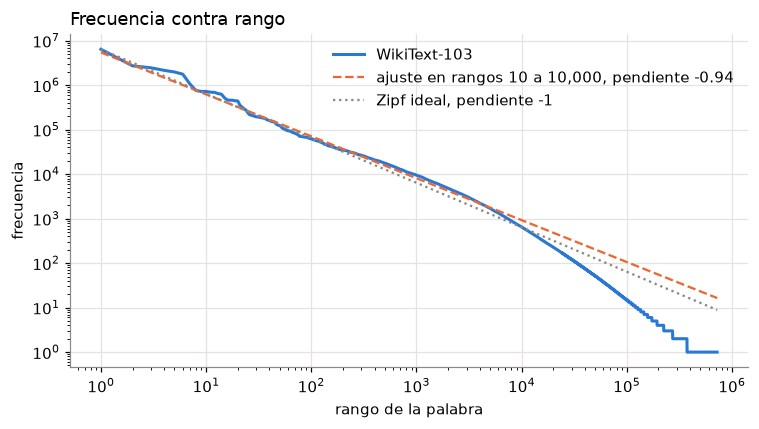

In [8]:
rangos = np.arange(1, len(CONTEOS) + 1)

def ajuste_zipf(desde, hasta):
    r = np.unique(np.logspace(np.log10(desde), np.log10(hasta), 200).astype(int))
    return np.polyfit(np.log10(r), np.log10(CONTEOS[r - 1]), 1)

pendiente, intercepto = ajuste_zipf(10, 10000)
pendiente_cola, _ = ajuste_zipf(10000, 300000)
cobertura = np.cumsum(CONTEOS) / CONTEOS.sum()
for k in [10, 1000, 30000]:
    print(f"Las {k:,} palabras más frecuentes cubren {100 * cobertura[k - 1]:.1f} % de los tokens")
print(f"Pendiente log-log entre los rangos 10 y 10,000: {pendiente:.3f}")
print(f"Pendiente log-log entre los rangos 10,000 y 300,000: {pendiente_cola:.3f}")
print(f"Palabras que aparecen una sola vez: {(CONTEOS == 1).sum():,}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(rangos, CONTEOS, color=COLOR["sgns"], label="WikiText-103")
ax.loglog(rangos, 10 ** intercepto * rangos ** pendiente, color=COLOR["gensim"], ls="--", lw=1.5,
          label=f"ajuste en rangos 10 a 10,000, pendiente {pendiente:.2f}")
ax.loglog(rangos, CONTEOS[0] / rangos, color="#8a8984", ls=":", lw=1.5, label="Zipf ideal, pendiente -1")
ax.set_xlabel("rango de la palabra")
ax.set_ylabel("frecuencia")
ax.set_title("Frecuencia contra rango", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figuras/zipf.png")
plt.show()

La ley de Zipf se cumple en la zona central de la distribución: entre los rangos 10 y 10,000 la pendiente log-log es −0.94, muy cerca del −1 ideal. En la cola, a partir del rango 10,000, la curva cae más rápido, con pendiente −1.71, porque el corpus es finito y las palabras raras aparecen una sola vez: 351,012 de las 725,273 palabras distintas, el 48 %, son hapax. La concentración es muy alta: las 10 palabras más frecuentes cubren el 24.6 % de los tokens, las 1,000 más frecuentes el 64.0 % y las 30,000 más frecuentes el 94.6 %.

### 2.5 Vocabulario y min_count

In [9]:
filas = []
for mc in [1, 3, 5, 10, 20, 50]:
    V = int((CONTEOS >= mc).sum())
    filas.append({"min_count": mc, "vocabulario": V,
                  "% tokens desconocidos": round(100 * CONTEOS[V:].sum() / CONTEOS.sum(), 3),
                  "% del vocabulario en GloVe": round(100 * np.mean([w in glove.key_to_index for w in PALABRAS[:V]]), 1)})
display(pd.DataFrame(filas))

MIN_COUNT = 5
V_BASE = int((CONTEOS >= MIN_COUNT).sum())
W2I = {w: i for i, w in enumerate(PALABRAS[:V_BASE])}
UNK = V_BASE

def a_ids(tokens, w2i=W2I):
    return [w2i.get(w, UNK) for w in tokens]

texto = "The Valkyria series is a tactical role-playing game developed by Sega in 2010."
print(texto)
print(tokenizar(texto))
print(a_ids(tokenizar(texto)))

,min_count,vocabulario,% tokens desconocidos,% del vocabulario en GloVe
0,1,725273,0.000,36.8
1,3,273143,0.654,71.2
2,5,194103,0.971,82.0
3,10,127819,1.482,91.3
4,20,86083,2.154,96.1
5,50,51317,3.434,99.3


The Valkyria series is a tactical role-playing game developed by Sega in 2010.
['the', 'valkyria', 'series', 'is', 'a', 'tactical', 'role-playing', 'game', 'developed', 'by', 'sega', 'in', '2010']
[0, 47414, 91, 14, 5, 4945, 6306, 59, 429, 13, 4698, 3, 274]


Subir el umbral reduce el vocabulario mucho más rápido de lo que aumentan los desconocidos: con min_count 5 quedan 194,103 palabras y solo el 0.97 % de los tokens queda fuera, y con min_count 20 el vocabulario baja a 86,083 palabras con 2.15 % de desconocidos. La mayoría de las palabras eliminadas son nombres propios, errores y números raros, por eso al subir el umbral también crece la fracción del vocabulario que existe en GloVe. Se usa min_count 5 como base, el valor por defecto de Word2Vec. Las iteraciones prueban también 20.

### 2.6 Submuestreo de palabras frecuentes

Word2Vec descarta cada aparición de una palabra w con frecuencia relativa f con probabilidad 1 − P, donde P es la raíz de f/t más 1, multiplicada por t/f, y t es un umbral alrededor de 0.0001. Es la fórmula del código original y de gensim. Las frecuencias se calculan sobre los tokens del vocabulario con min_count 5.

In [10]:
def prob_conservar(conteos, t):
    f = conteos / conteos.sum()
    return np.minimum((np.sqrt(f / t) + 1) * t / f, 1.0)

filas = []
for t in [1e-3, 1e-4, 1e-5]:
    p = prob_conservar(CONTEOS[:V_BASE], t)
    fila = {"t": t}
    for w in ["the", "of", "and", "in", "king", "computer"]:
        fila[f"% descartado {w}"] = round(100 * (1 - p[W2I[w]]), 1)
    fila["% tokens descartados"] = round(100 * (1 - (p * CONTEOS[:V_BASE]).sum() / CONTEOS[:V_BASE].sum()), 1)
    filas.append(fila)
display(pd.DataFrame(filas))

,t,% descartado the,% descartado of,% descartado and,% descartado in,% descartado king,% descartado computer,% tokens descartados
0,0.00100,87.3,79.4,78.1,76.4,0.0,0.0,22.5
1,0.00010,96.3,94.1,93.8,93.4,26.2,0.0,39.7
2,0.00001,98.8,98.2,98.1,98.0,81.9,45.0,63.8


Con el umbral habitual de 0.0001 se descarta el 96.3 % de las apariciones de the, el 94.1 % de of y el 93.8 % de and, mientras que una palabra de contenido como computer nunca se descarta. En total se elimina cerca del 40 % de los tokens. El submuestreo ayuda por tres razones: las palabras funcionales aportan poca información sobre el significado de sus vecinas, así que sus pares son casi ruido, reducir su frecuencia acelera cada epoch, y al quitarlas de la ventana, las palabras de contenido quedan más cerca entre sí, lo que amplía el contexto útil. También equilibra el entrenamiento, porque sin submuestreo los vectores de las palabras frecuentes recibirían la mayoría de las actualizaciones.

### 2.7 Pares de skip-gram

Los pares se generan en la GPU con operaciones vectorizadas. Para cada distancia d entre 1 y la ventana se emparejan las posiciones i e i+d que pertenecen al mismo párrafo, en ambos sentidos. Como en Word2Vec, la ventana de cada palabra central se reduce a un valor aleatorio b entre 1 y la ventana máxima, lo que da más peso a los contextos cercanos. El submuestreo se aplica antes de formar las ventanas, así que las palabras descartadas no ocupan lugar y la ventana alcanza palabras más lejanas.

In [11]:
def generar_pares(ids, frase, ventana, p_conservar=None, dinamica=True):
    # submuestreo antes de ventanas
    if p_conservar is not None:
        mascara = torch.rand(len(ids), device=ids.device) < p_conservar[ids]
        ids, frase = ids[mascara], frase[mascara]
    if dinamica:
        b = torch.randint(1, ventana + 1, (len(ids),), device=ids.device)
    else:
        b = torch.full((len(ids),), ventana, device=ids.device)
    centros, contextos = [], []
    for d in range(1, ventana + 1):
        misma = frase[:-d] == frase[d:]
        izq = misma & (b[:-d] >= d)
        der = misma & (b[d:] >= d)
        centros += [ids[:-d][izq], ids[d:][der]]
        contextos += [ids[d:][izq], ids[:-d][der]]
    return torch.cat(centros), torch.cat(contextos)

def trozos(n, tam=10_000_000):
    return [(i, min(i + tam, n)) for i in range(0, n, tam)]

frase_demo = torch.tensor([W2I[w] for w in "the king of france ruled".split()], device=DEVICE)
c, o = generar_pares(frase_demo, torch.zeros(5, dtype=torch.int32, device=DEVICE), 2, dinamica=False)
print([(PALABRAS[i], PALABRAS[j]) for i, j in zip(c.tolist(), o.tolist())])

[('the', 'king'), ('king', 'of'), ('of', 'france'), ('france', 'ruled'), ('king', 'the'), ('of', 'king'), ('france', 'of'), ('ruled', 'france'), ('the', 'of'), ('king', 'france'), ('of', 'ruled'), ('of', 'the'), ('france', 'king'), ('ruled', 'of')]

In [12]:
mascara = IDS < V_BASE
ids_gpu = torch.from_numpy(IDS[mascara]).to(DEVICE)
frase_gpu = torch.from_numpy(FRASE[mascara]).to(DEVICE)
p_gpu = torch.tensor(prob_conservar(CONTEOS[:V_BASE], 1e-4), dtype=torch.float32, device=DEVICE)

VENTANA = 5
largos_vocab = np.bincount(FRASE[mascara], minlength=len(largos))
formula = sum(2 * np.maximum(largos_vocab - d, 0).sum() for d in range(1, VENTANA + 1))

fijar_semilla()
conteo_pares = {}
for nombre, p, din in [("ventana fija, sin submuestreo", None, False), ("ventana dinámica, sin submuestreo", None, True),
                       ("ventana fija, con submuestreo", p_gpu, False), ("ventana dinámica, con submuestreo", p_gpu, True)]:
    total = 0
    for ini, fin in trozos(len(ids_gpu)):
        c, o = generar_pares(ids_gpu[ini:fin], frase_gpu[ini:fin], VENTANA, p, din)
        total += len(c)
    conteo_pares[nombre] = total
    print(f"{nombre:36s}: {total:>13,} pares por epoch")
print(f"Fórmula para ventana fija sin submuestreo: {formula:,} pares")
print(f"Tokens en el vocabulario: {len(ids_gpu):,}")
del ids_gpu, frase_gpu, c, o
torch.cuda.empty_cache()

ventana fija, sin submuestreo       :   812,259,808 pares por epoch
ventana dinámica, sin submuestreo   :   490,710,518 pares por epoch


ventana fija, con submuestreo       :   480,029,354 pares por epoch
ventana dinámica, con submuestreo   :   291,361,727 pares por epoch
Fórmula para ventana fija sin submuestreo: 812,260,048 pares
Tokens en el vocabulario: 83,761,486


Con ventana 5 y min_count 5, el corpus produce 812.3 millones de pares por epoch con ventana fija y sin submuestreo. La fórmula exacta da 240 pares más, que son los que cruzan los cortes entre trozos de 10 millones de tokens. La ventana dinámica reduce los pares a 490.7 millones, el 60 %, porque una ventana uniforme entre 1 y 5 tiene en promedio 3 palabras por lado. El submuestreo, con t de 0.0001, los reduce a 480.0 millones con ventana fija y a 291.4 millones con ventana dinámica, que es la cantidad real de pares por epoch de la configuración base.

## 3. Investigación: embeddings en PyTorch y gensim

### nn.Embedding y nn.Embedding.from_pretrained

nn.Embedding es una tabla de búsqueda: guarda una matriz de num_embeddings filas por embedding_dim columnas y, al recibir un tensor de IDs enteros, devuelve las filas correspondientes. Equivale a multiplicar un vector one-hot por la matriz, pero sin construir el one-hot. num_embeddings es el tamaño del vocabulario y embedding_dim la dimensión de cada vector. padding_idx indica un ID cuya fila se inicializa en ceros y no recibe gradiente, útil para rellenar secuencias de distinto largo. Con sparse=True el gradiente de la tabla es un tensor disperso que solo contiene las filas usadas en el lote. Con vocabularios grandes ahorra memoria y tiempo, pero solo lo aceptan optimizadores como SGD, SparseAdam y Adagrad. Por defecto los pesos se inicializan con una normal estándar.

nn.Embedding.from_pretrained crea la capa a partir de una matriz ya entrenada. Su parámetro freeze, verdadero por defecto, deja requires_grad en False para que la tabla no cambie durante el entrenamiento. Con freeze=False la tabla se ajusta junto con el resto del modelo, lo que se conoce como fine-tuning. También acepta padding_idx y sparse.

In [13]:
emb = nn.Embedding(num_embeddings=6, embedding_dim=3, padding_idx=0)
x = torch.tensor([[1, 2, 0], [4, 0, 0]])
print("salida:", tuple(emb(x).shape), "| fila de padding:", emb.weight[0].tolist())
emb(x).sum().backward()
print("gradiente de la fila 0:", emb.weight.grad[0].tolist(), "| fila 1:", emb.weight.grad[1].tolist())

emb_disperso = nn.Embedding(6, 3, sparse=True)
emb_disperso(torch.tensor([1, 1, 4])).sum().backward()
print("gradiente disperso:", emb_disperso.weight.grad.is_sparse, emb_disperso.weight.grad.coalesce().indices().tolist())

pesos = torch.tensor(glove[["king", "queen", "man"]])
congelada = nn.Embedding.from_pretrained(pesos, freeze=True)
ajustable = nn.Embedding.from_pretrained(pesos, freeze=False)
print("freeze=True:", congelada.weight.requires_grad, "| freeze=False:", ajustable.weight.requires_grad)

salida: (2, 3, 3) | fila de padding: [0.0, 0.0, 0.0]
gradiente de la fila 0: [0.0, 0.0, 0.0] | fila 1: [1.0, 1.0, 1.0]
gradiente disperso: True [[1, 4]]
freeze=True: False | freeze=False: True


### nn.EmbeddingBag y offsets

nn.EmbeddingBag combina la búsqueda en la tabla con una agregación por bolsa, sin crear el tensor intermedio de vectores por palabra. Su parámetro mode define la agregación: mean promedia los vectores de cada bolsa, sum los suma y max toma el máximo por dimensión. La entrada puede ser un tensor 2D de bolsas del mismo largo, o un tensor 1D con todos los IDs concatenados y un tensor offsets que indica dónde empieza cada bolsa. Así se procesan documentos de distinto largo sin relleno. También acepta padding_idx, cuyas apariciones se excluyen del promedio, per_sample_weights para ponderar cada palabra con mode sum, y from_pretrained con freeze, igual que nn.Embedding. En la sección 6 se usa con mode mean para representar cada noticia como el promedio de los vectores de sus palabras.

In [14]:
tabla = torch.arange(30, dtype=torch.float32).view(10, 3)
ids_bolsas = torch.tensor([1, 2, 4, 5, 4, 3, 2, 9])
offsets = torch.tensor([0, 4])
for modo in ["mean", "sum", "max"]:
    bolsa = nn.EmbeddingBag.from_pretrained(tabla, mode=modo)
    print(f"{modo:4s}:", bolsa(ids_bolsas, offsets).tolist())
print("mean manual de la primera bolsa:", tabla[[1, 2, 4, 5]].mean(0).tolist())

mean: [[9.0, 10.0, 11.0], [13.5, 14.5, 15.5]]
sum : [[36.0, 40.0, 44.0], [54.0, 58.0, 62.0]]
max : [[15.0, 16.0, 17.0], [27.0, 28.0, 29.0]]
mean manual de la primera bolsa: [9.0, 10.0, 11.0]


### Herramientas de gensim

gensim.models.Word2Vec entrena Word2Vec en CPU con código en C. Sus parámetros principales son:

- vector_size: dimensión de los vectores.
- window: ventana máxima de contexto.
- min_count: frecuencia mínima para entrar al vocabulario.
- sg: 1 para skip-gram y 0 para CBOW.
- negative: número de negativos.
- sample: umbral de submuestreo.
- alpha y min_alpha: learning rate inicial y final, con decaimiento lineal.
- epochs y workers: número de pasadas y de hilos.
- compute_loss y callbacks: registran la pérdida y ejecutan código al final de cada epoch.

 El corpus se pasa como un iterable de listas de tokens, por ejemplo LineSentence, que lee un archivo con un párrafo tokenizado por línea.

KeyedVectors guarda los vectores con su vocabulario y sirve para cualquier modelo: most_similar resuelve analogías con 3CosAdd usando positive y negative, most_similar_cosmul usa 3CosMul, evaluate_word_analogies calcula el accuracy en questions-words.txt con restrict_vocab, y evaluate_word_pairs devuelve las correlaciones de Pearson y Spearman con un benchmark de similitud. add_vectors permite construir un KeyedVectors con vectores entrenados en PyTorch, y save y load guardan el formato .kv. gensim.downloader.load descarga modelos preentrenados como GloVe.

### Conceptos

CBOW predice la palabra central a partir del promedio de los vectores de su contexto, mientras que skip-gram predice cada palabra del contexto a partir de la palabra central. CBOW es más rápido porque hace una predicción por posición, pero promedia el contexto y suaviza la información de palabras raras. Skip-gram genera un par por cada palabra del contexto, es más lento y suele representar mejor las palabras poco frecuentes.

Word2Vec usa dos matrices porque cada palabra cumple dos roles: W da el vector de la palabra cuando es central y W' cuando es contexto, y la probabilidad de que c aparezca junto a w depende del producto punto entre el vector de entrada de w y el de salida de c. Con una sola matriz el producto de una palabra consigo misma sería alto y el modelo predeciría que cada palabra aparece junto a sí misma, lo cual es raro en el texto. Al terminar se conserva W, la matriz de entrada, aunque algunas variantes promedian o suman ambas.

Word2Vec es un modelo predictivo: recorre el texto ventana por ventana y ajusta los vectores para predecir el contexto, con negative sampling para no calcular un softmax sobre todo el vocabulario. GloVe se basa en conteos: primero construye la matriz global de co-ocurrencias X y luego ajusta vectores cuyo producto punto más dos sesgos aproxime log X, con una ponderación que limita el peso de los pares muy frecuentes. Levy y Goldberg mostraron que SGNS factoriza implícitamente una matriz de PMI desplazada, así que ambos aprovechan la misma estadística por caminos distintos.

## 4. Construcción y entrenamiento de los embeddings

### 4.1 Funciones de evaluación

Las analogías se evalúan en la GPU con una implementación propia que admite 3CosAdd y 3CosMul y un vocabulario restringido. Como en gensim, una pregunta solo se evalúa si sus cuatro palabras están en el vocabulario restringido, la respuesta se busca dentro de ese vocabulario y se excluyen las tres palabras de la pregunta. Durante la selección de configuraciones se usa el vocabulario de las 30,000 palabras más frecuentes de cada modelo, el criterio por defecto de evaluate_word_analogies. Las primeras 5 categorías son semánticas y las 9 restantes sintácticas.

In [15]:
def cargar_analogias(ruta):
    secciones, actual = {}, None
    with open(ruta, encoding="utf-8") as f:
        for linea in f:
            if linea.startswith(":"):
                actual = linea[1:].strip()
                secciones[actual] = []
            else:
                secciones[actual].append(linea.lower().split())
    return secciones

ANALOGIAS = cargar_analogias(RUTA_ANALOGIAS)
CATEGORIAS = list(ANALOGIAS)
SEMANTICAS = CATEGORIAS[:5]
print(len(CATEGORIAS), "categorías,", sum(len(v) for v in ANALOGIAS.values()), "analogías")

def a_keyed(vectores, palabras):
    kv = KeyedVectors(vectores.shape[1])
    kv.add_vectors(list(palabras), vectores)
    return kv

@torch.no_grad()
def evaluar_analogias(kv, vocab=None, metodo="add"):
    vocab = list(vocab) if vocab is not None else kv.index_to_key[:30000]
    w2i = {w: i for i, w in enumerate(vocab)}
    E = F.normalize(torch.tensor(kv[vocab], device=DEVICE), dim=1)
    res = {}
    for cat, preguntas in ANALOGIAS.items():
        q = [[w2i[w] for w in p] for p in preguntas if all(w in w2i for w in p)]
        aciertos = 0
        for i in range(0, len(q), 2048):
            t = torch.tensor(q[i:i + 2048], device=DEVICE)
            a, b, c = E[t[:, 0]] @ E.T, E[t[:, 1]] @ E.T, E[t[:, 2]] @ E.T
            if metodo == "add":
                s = b - a + c
            else:
                s = (1 + b) / 2 * (1 + c) / 2 / ((1 + a) / 2 + 1e-6)
            # excluir palabras de consulta
            s.scatter_(1, t[:, :3], -1e9)
            aciertos += (s.argmax(1) == t[:, 3]).sum().item()
        res[cat] = {"aciertos": aciertos, "evaluadas": len(q), "total": len(preguntas)}
    return res

def resumen_analogias(res):
    def acc(cats):
        n = sum(res[c]["evaluadas"] for c in cats)
        return sum(res[c]["aciertos"] for c in cats) / max(n, 1)
    return {"sem": acc(SEMANTICAS), "sin": acc(CATEGORIAS[5:]), "total": acc(CATEGORIAS),
            "cobertura": sum(r["evaluadas"] for r in res.values()) / sum(r["total"] for r in res.values())}

def spearman(kv, ruta):
    return float(kv.evaluate_word_pairs(ruta)[1].statistic)

CONTROL = ["king", "france", "computer", "good", "january", "run"]

def vecinos(kv, palabras=CONTROL, k=5):
    return {w: [x for x, _ in kv.most_similar(w, topn=k)] for w in palabras}

14 categorías, 19544 analogías


Antes de usarla se verifica que la evaluación propia coincide con evaluate_word_analogies de gensim sobre GloVe con el mismo vocabulario de 30,000 palabras.

In [16]:
t0 = time.time()
acc_gensim, secciones = glove.evaluate_word_analogies(RUTA_ANALOGIAS, restrict_vocab=30000)
t_gensim = time.time() - t0
t0 = time.time()
propio = resumen_analogias(evaluar_analogias(glove))
t_propio = time.time() - t0
print(f"gensim: {acc_gensim:.4f} en {t_gensim:.1f} s | propia: {propio['total']:.4f} en {t_propio:.1f} s")
print(f"GloVe WordSim-353: {spearman(glove, RUTA_WS353):.4f}")

gensim: 0.6549 en 4.7 s | propia: 0.6549 en 0.3 s
GloVe WordSim-353: 0.5327


### 4.2 Skip-gram con negative sampling en PyTorch

El modelo tiene dos tablas nn.Embedding: entrada, para la palabra central, y salida, para contextos y negativos. Para cada par se maximiza el log sigmoide de u_o · v_c más la suma del log sigmoide de −u_n · v_c sobre k negativos, muestreados de la distribución unigrama elevada a 0.75. Como en el código original, la tabla de entrada se inicializa uniforme en ±0.5/d y la de salida en ceros.

El entrenamiento reproduce la regla de Word2Vec: SGD sin momentum con learning rate inicial de 0.025 que decae linealmente hasta 0.0001 de su valor, y la pérdida se suma sobre el lote para que cada par aporte un gradiente completo, como en la actualización par por par del original. Las tablas usan sparse=True, así cada paso solo toca las filas presentes en el lote. Los pares se generan y barajan en la GPU por trozos de 10 millones de tokens y se entrenan en lotes de 32,768 pares. En cada epoch se mide el tiempo de entrenamiento sin la evaluación.

Entrenar por lotes tiene una diferencia con el original: una palabra muy frecuente como the aparece miles de veces en un mismo lote como contexto o negativo, y su fila recibe la suma de todos esos gradientes en un solo paso, cuando en Word2Vec cada actualización ve el vector ya corregido. En pruebas previas eso hizo divergir a NaN las configuraciones con 15 negativos, t de 0.001 o learning rate de 0.05. Para evitarlo, el gradiente acumulado de cada fila se recorta a ±5 por componente antes del paso de SGD. El recorte solo afecta a las palabras más frecuentes y en la configuración base no cambió el accuracy de analogías.

In [17]:
class SkipGramNS(nn.Module):
    def __init__(self, n_palabras, dim):
        super().__init__()
        self.entrada = nn.Embedding(n_palabras, dim, sparse=True)
        self.salida = nn.Embedding(n_palabras, dim, sparse=True)
        nn.init.uniform_(self.entrada.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.salida.weight)

    def forward(self, centro, contexto, negativos):
        v = self.entrada(centro)
        u = self.salida(contexto)
        u_neg = self.salida(negativos)
        pos = F.logsigmoid((v * u).sum(1))
        neg = F.logsigmoid(-torch.bmm(u_neg, v.unsqueeze(2)).squeeze(2)).sum(1)
        return -(pos + neg)

def preparar_corpus(fraccion, min_count):
    n_tok = int(largos[:int(len(largos) * fraccion)].sum())
    V = int((CONTEOS >= min_count).sum())
    m = IDS[:n_tok] < V
    ids = torch.from_numpy(IDS[:n_tok][m]).to(DEVICE)
    frase = torch.from_numpy(FRASE[:n_tok][m]).to(DEVICE)
    return ids, frase, V, n_tok

In [18]:
REGISTROS, KV_ITER = [], {}

def guardar_registros():
    with open("resultados/iteraciones.json", "w", encoding="utf-8") as f:
        json.dump({"registros": REGISTROS, "hardware": HARDWARE}, f, indent=1, default=str)

def registrar_epoch(hist, kv, perdida, t_epoch, pares):
    kv.fill_norms(force=True)
    an = resumen_analogias(evaluar_analogias(kv))
    hist["loss"].append(perdida)
    hist["sem"].append(an["sem"])
    hist["sin"].append(an["sin"])
    hist["total"].append(an["total"])
    hist["ws353"].append(spearman(kv, RUTA_WS353))
    hist["vecinos"].append(vecinos(kv))
    hist["t_epoch"].append(t_epoch)
    hist["pares"].append(pares)

def entrenar_sgns(nombre, cfg, verbose=True):
    fijar_semilla()
    ids, frase, V, n_tok = preparar_corpus(cfg["fraccion"], cfg["min_count"])
    p_conservar = torch.tensor(prob_conservar(CONTEOS[:V], cfg["t"]), dtype=torch.float32, device=DEVICE)
    p_neg = torch.tensor(CONTEOS[:V], dtype=torch.float64, device=DEVICE) ** 0.75
    cdf_neg = (torch.cumsum(p_neg, 0) / p_neg.sum()).float()
    cdf_neg[-1] = 1.0
    modelo = SkipGramNS(V, cfg["dim"]).to(DEVICE)
    opt = torch.optim.SGD(modelo.parameters(), lr=cfg["lr"])
    partes = trozos(len(ids))
    hist = {k: [] for k in ["loss", "sem", "sin", "total", "ws353", "vecinos", "t_epoch", "pares"]}
    torch.cuda.reset_peak_memory_stats()

    for epoch in range(cfg["epochs"]):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        suma, n = torch.zeros((), device=DEVICE), 0
        for j, (ini, fin) in enumerate(partes):
            c, o = generar_pares(ids[ini:fin], frase[ini:fin], cfg["ventana"], p_conservar)
            perm = torch.randperm(len(c), device=DEVICE)
            c, o = c[perm], o[perm]
            for i in range(0, len(c), cfg["batch"]):
                # decaimiento lineal del lr
                progreso = (epoch + (j + i / len(c)) / len(partes)) / cfg["epochs"]
                opt.param_groups[0]["lr"] = cfg["lr"] * max(1 - progreso, 1e-4)
                cb, ob = c[i:i + cfg["batch"]], o[i:i + cfg["batch"]]
                # negativos por unigrama^0.75
                neg = torch.searchsorted(cdf_neg, torch.rand(len(cb), cfg["negativos"], device=DEVICE))
                perdida = modelo(cb, ob, neg)
                opt.zero_grad()
                perdida.sum().backward()
                # recorte por fila
                for p in modelo.parameters():
                    p.grad = p.grad.coalesce()
                    p.grad.values().clamp_(-cfg["recorte"], cfg["recorte"])
                opt.step()
                suma += perdida.detach().sum()
                n += len(cb)
        torch.cuda.synchronize()
        t_epoch = time.perf_counter() - t0

        kv = a_keyed(modelo.entrada.weight.detach().cpu().numpy(), PALABRAS[:V])
        registrar_epoch(hist, kv, (suma / n).item(), t_epoch, n)
        if verbose:
            print(f"[{nombre}] epoch {epoch + 1}/{cfg['epochs']} | loss {hist['loss'][-1]:.4f} | sem {hist['sem'][-1]:.4f} | "
                  f"sin {hist['sin'][-1]:.4f} | total {hist['total'][-1]:.4f} | WS353 {hist['ws353'][-1]:.4f} | "
                  f"{n / 1e6:.0f} M pares | {t_epoch:.1f} s")

    reg = {"nombre": nombre, "cfg": cfg, "tokens": n_tok, "tokens_vocab": len(ids), "vocab": V, "hist": hist,
           "t_epoch": float(np.mean(hist["t_epoch"])), "t_total": float(np.sum(hist["t_epoch"])),
           "mem_pico_mb": torch.cuda.max_memory_allocated() / 2**20}
    REGISTROS.append(reg)
    KV_ITER[nombre] = kv
    guardar_registros()
    del modelo, opt, ids, frase
    torch.cuda.empty_cache()
    return reg

def resumen_config(cfg):
    return (f"{100 * cfg['fraccion']:.0f} % corpus, d {cfg['dim']}, ventana {cfg['ventana']}, k {cfg['negativos']}, "
            f"t {cfg['t']:g}, min_count {cfg['min_count']}, lr {cfg['lr']:g}, {cfg['epochs']} epochs")

ETIQUETA = {"S1": "base", "S2": "dimensión 50", "S3": "dimensión 300", "S4": "25 % del corpus", "S5": "50 % del corpus",
            "S6": "ventana 2", "S7": "ventana 10", "S8": "15 negativos", "S9": "t 0.001", "S10": "t 0.00001",
            "S11": "min_count 20", "S12": "lr 0.05", "S13": "10 epochs", "S14": "combinada"}

def tabla_iteraciones():
    filas = []
    for r in REGISTROS:
        h = r["hist"]
        filas.append({"iteración": r["nombre"], "cambio": ETIQUETA[r["nombre"]], "configuración": resumen_config(r["cfg"]),
                      "tokens corpus": f"{r['tokens']:,}",
                      "vocabulario": f"{r['vocab']:,}", "loss final": round(h["loss"][-1], 4),
                      "sem": round(h["sem"][-1], 4), "sin": round(h["sin"][-1], 4), "total": round(h["total"][-1], 4),
                      "WS353": round(h["ws353"][-1], 4), "M pares por epoch": round(np.mean(h["pares"]) / 1e6),
                      "s por epoch": round(r["t_epoch"], 1), "total s": round(r["t_total"]),
                      "memoria pico MB": round(r["mem_pico_mb"])})
    df = pd.DataFrame(filas)
    with pd.option_context("display.max_colwidth", None):
        display(df)
    return df

### 4.3 Iteraciones

S1 es la configuración base, con los valores por defecto de Word2Vec: dimensión 100, ventana 5, 5 negativos, t de 0.0001, min_count 5, learning rate 0.025 y 5 epochs sobre el corpus completo. Cada iteración siguiente cambia un solo hiperparámetro respecto a S1: S2 y S3 la dimensión, S4 y S5 el tamaño del corpus, S6 y S7 la ventana, S8 los negativos, S9 y S10 el umbral de submuestreo, S11 el min_count, S12 el learning rate y S13 el número de epochs. S14 combina los cambios que mejoraron a S1 manteniendo la dimensión 100. La selección usa solo WordSim-353 y questions-words.txt, con el promedio de ambos como criterio.

In [19]:
BASE = dict(fraccion=1.0, min_count=5, dim=100, ventana=5, negativos=5, t=1e-4, lr=0.025, epochs=5, batch=32768, recorte=5.0)
CFG_SGNS = {
    "S1": BASE,
    "S2": dict(BASE, dim=50),
    "S3": dict(BASE, dim=300),
    "S4": dict(BASE, fraccion=0.25),
    "S5": dict(BASE, fraccion=0.5),
    "S6": dict(BASE, ventana=2),
    "S7": dict(BASE, ventana=10),
    "S8": dict(BASE, negativos=15),
    "S9": dict(BASE, t=1e-3),
    "S10": dict(BASE, t=1e-5),
    "S11": dict(BASE, min_count=20),
    "S12": dict(BASE, lr=0.05),
    "S13": dict(BASE, epochs=10),
}
for nombre, cfg in CFG_SGNS.items():
    print("=" * 20, nombre, "|", resumen_config(cfg))
    entrenar_sgns(nombre, cfg)

==================== S1 | 100 % corpus, d 100, ventana 5, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs


[S1] epoch 1/5 | loss 2.3211 | sem 0.1977 | sin 0.3200 | total 0.2807 | WS353 0.6186 | 291 M pares | 32.5 s


[S1] epoch 2/5 | loss 2.2062 | sem 0.2623 | sin 0.4245 | total 0.3723 | WS353 0.6468 | 291 M pares | 32.2 s


[S1] epoch 3/5 | loss 2.1781 | sem 0.3088 | sin 0.4978 | total 0.4370 | WS353 0.6635 | 291 M pares | 32.3 s


[S1] epoch 4/5 | loss 2.1622 | sem 0.3742 | sin 0.5497 | total 0.4933 | WS353 0.6776 | 291 M pares | 32.4 s


...

[S13] epoch 6/10 | loss 2.1526 | sem 0.3497 | sin 0.5144 | total 0.4614 | WS353 0.6667 | 291 M pares | 35.6 s


[S13] epoch 7/10 | loss 2.1450 | sem 0.3814 | sin 0.5389 | total 0.4882 | WS353 0.6722 | 291 M pares | 36.3 s


[S13] epoch 8/10 | loss 2.1393 | sem 0.4115 | sin 0.5580 | total 0.5108 | WS353 0.6888 | 291 M pares | 36.2 s


[S13] epoch 9/10 | loss 2.1362 | sem 0.4250 | sin 0.5838 | total 0.5327 | WS353 0.6933 | 291 M pares | 36.2 s


[S13] epoch 10/10 | loss 2.1375 | sem 0.4396 | sin 0.5984 | total 0.5473 | WS353 0.7008 | 291 M pares | 35.7 s


S14 se arma de forma automática: de las iteraciones S6 a S13, que cambian un hiperparámetro sin tocar dimensión ni corpus, se toman los cambios cuyo puntaje superó a S1, y si dos cambian el mismo hiperparámetro se queda el mejor.

In [20]:
def puntaje(r):
    return (r["hist"]["total"][-1] + r["hist"]["ws353"][-1]) / 2

def registro(nombre):
    return next(r for r in REGISTROS if r["nombre"] == nombre)

cambios = {}
for nombre in ["S6", "S7", "S8", "S9", "S10", "S11", "S12", "S13"]:
    clave = next(k for k in BASE if CFG_SGNS[nombre][k] != BASE[k])
    p = puntaje(registro(nombre))
    print(f"{nombre}: {clave} = {CFG_SGNS[nombre][clave]} | puntaje {p:.4f} frente a {puntaje(registro('S1')):.4f} de S1")
    if p > puntaje(registro("S1")) and (clave not in cambios or p > cambios[clave][1]):
        cambios[clave] = (CFG_SGNS[nombre][clave], p)
CFG_SGNS["S14"] = dict(BASE, **{k: v for k, (v, _) in cambios.items()})
print("=" * 20, "S14 |", resumen_config(CFG_SGNS["S14"]))
entrenar_sgns("S14", CFG_SGNS["S14"])
tabla_sgns = tabla_iteraciones()
tabla_sgns.to_csv("resultados/tabla_iteraciones.csv", index=False, encoding="utf-8")

S6: ventana = 2 | puntaje 0.5969 frente a 0.6072 de S1
S7: ventana = 10 | puntaje 0.5944 frente a 0.6072 de S1
S8: negativos = 15 | puntaje 0.6155 frente a 0.6072 de S1
S9: t = 0.001 | puntaje 0.6071 frente a 0.6072 de S1
S10: t = 1e-05 | puntaje 0.5854 frente a 0.6072 de S1
S11: min_count = 20 | puntaje 0.6091 frente a 0.6072 de S1
S12: lr = 0.05 | puntaje 0.6067 frente a 0.6072 de S1
S13: epochs = 10 | puntaje 0.6241 frente a 0.6072 de S1
==================== S14 | 100 % corpus, d 100, ventana 5, k 15, t 0.0001, min_count 20, lr 0.025, 10 epochs


[S14] epoch 1/10 | loss 3.3021 | sem 0.2289 | sin 0.3213 | total 0.2915 | WS353 0.6344 | 285 M pares | 65.5 s


[S14] epoch 2/10 | loss 3.1909 | sem 0.2950 | sin 0.3578 | total 0.3376 | WS353 0.6394 | 285 M pares | 64.7 s


[S14] epoch 3/10 | loss 3.1631 | sem 0.3152 | sin 0.4197 | total 0.3861 | WS353 0.6627 | 285 M pares | 62.1 s


[S14] epoch 4/10 | loss 3.1445 | sem 0.3471 | sin 0.4462 | total 0.4143 | WS353 0.6694 | 285 M pares | 64.0 s


...

[S14] epoch 7/10 | loss 3.1098 | sem 0.4273 | sin 0.5393 | total 0.5033 | WS353 0.6671 | 285 M pares | 64.4 s


[S14] epoch 8/10 | loss 3.1031 | sem 0.4631 | sin 0.5644 | total 0.5318 | WS353 0.6710 | 285 M pares | 64.2 s


[S14] epoch 9/10 | loss 3.0995 | sem 0.4754 | sin 0.5870 | total 0.5511 | WS353 0.6829 | 285 M pares | 63.2 s


[S14] epoch 10/10 | loss 3.1013 | sem 0.5047 | sin 0.6012 | total 0.5702 | WS353 0.6807 | 285 M pares | 63.7 s


,iteración,cambio,configuración,tokens corpus,vocabulario,loss final,sem,sin,total,WS353,M pares por epoch,s por epoch,total s,memoria pico MB
0,S1,base,"100 % corpus, d 100, ventana 5, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.1571,0.4061,0.5796,0.5238,0.6906,291,32.3,161,4136
1,S2,dimensión 50,"100 % corpus, d 50, ventana 5, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.1935,0.2810,0.4607,0.4029,0.6464,291,24.9,125,4050
2,S3,dimensión 300,"100 % corpus, d 300, ventana 5, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.1071,0.5653,0.6274,0.6074,0.6941,291,61.7,309,4482
3,S4,25 % del corpus,"25 % corpus, d 100, ventana 5, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","21,015,535","194,103",2.1499,0.2822,0.4290,0.3818,0.6368,72,8.2,41,3397
4,S5,50 % del corpus,"50 % corpus, d 100, ventana 5, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","42,291,631","194,103",2.1535,0.3722,0.5363,0.4835,0.6755,146,16.5,83,3657
5,S6,ventana 2,"100 % corpus, d 100, ventana 2, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.0435,0.3599,0.6011,0.5235,0.6703,148,17.1,85,2696
6,S7,ventana 10,"100 % corpus, d 100, ventana 10, k 5, t 0.0001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.2106,0.4112,0.5492,0.5048,0.6840,519,57.5,287,6429
7,S8,15 negativos,"100 % corpus, d 100, ventana 5, k 15, t 0.0001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",3.0664,0.4708,0.5882,0.5505,0.6806,291,63.1,316,4155
8,S9,t 0.001,"100 % corpus, d 100, ventana 5, k 5, t 0.001, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.1914,0.3934,0.5812,0.5208,0.6934,378,45.7,229,4999
9,S10,t 0.00001,"100 % corpus, d 100, ventana 5, k 5, t 1e-05, min_count 5, lr 0.025, 5 epochs","84,582,418","194,103",2.0869,0.4232,0.5370,0.5004,0.6704,170,20.6,103,2923


In [21]:
candidatos = [r for r in REGISTROS if r["cfg"]["dim"] == 100]
MEJOR = max(candidatos, key=puntaje)["nombre"]
REG_MEJOR = next(r for r in REGISTROS if r["nombre"] == MEJOR)
CFG_MEJOR = REG_MEJOR["cfg"]
print("Mejor configuración de dimensión 100:", MEJOR, "|", resumen_config(CFG_MEJOR), f"| puntaje {puntaje(REG_MEJOR):.4f}")
print("Mejor de todas:", max(REGISTROS, key=puntaje)["nombre"])
sgns = KV_ITER[MEJOR]
sgns.save("modelos/sgns_mejor.kv")

for epoch, v in enumerate(REG_MEJOR["hist"]["vecinos"], 1):
    print(f"epoch {epoch}:", " | ".join(f"{w}: {', '.join(l)}" for w, l in v.items()))

Mejor configuración de dimensión 100: S14 | 100 % corpus, d 100, ventana 5, k 15, t 0.0001, min_count 20, lr 0.025, 10 epochs | puntaje 0.6254
Mejor de todas: S3
epoch 1: king: ecgberht, harthacnut, 1199, dalyngrigge, eadred | france: spain, italy, belgium, nantes, bordeaux | computer: stored-program, spacewar, computers, pdp-1, mainframe | good: bad, perfect, luck, darn, weirdly | january: february, december, august, april, march | run: dantzler, inside-the-park, straight, truckers, running
epoch 2: king: hoots, gille-brighde, eadred, eadwig, bagler | france: spain, belgium, italy, limburg, luxembourg | computer: computing, stored-program, computers, programmable, pdp-1 | good: bad, perfect, decent, shitty, lousy | january: december, february, june, april, march | run: running, runs, bynum, 10-game, unearned
epoch 3: king: ballala, hoots, wardship, fiefdom, 1258 | france: spain, belgium, italy, britain, luxembourg | computer: computers, software, programmable, computing, minicomputer 

El modelo seleccionado es S14, con dimensión 100, ventana 5, 15 negativos, t de 0.0001, min_count 20 y 10 epochs: obtiene 57.0 % de accuracy total en analogías y 0.681 en WordSim-353. S13, con 10 epochs, tiene la mejor correlación en WordSim-353, 0.701, y S3, con dimensión 300, es la mejor iteración global con 60.7 % de analogías, pero queda fuera de la selección porque la comparación con GloVe y la clasificación usan dimensión 100.

Los efectos individuales respecto a S1 son claros. La dimensión es el factor más fuerte: 40.3 % con 50, 52.4 % con 100 y 60.7 % con 300. El tamaño del corpus también: 38.2 % con el 25 %, 48.4 % con el 50 % y 52.4 % con el 100 %. Más negativos suben el accuracy a 55.1 % y duplican el tiempo por epoch, y 10 epochs lo suben a 54.7 %. El learning rate de 0.05, t de 0.001 y min_count 20 casi no cambian el resultado, y t de 0.00001 lo empeora porque descarta demasiados tokens. La ventana cambia el tipo de relación aprendida: con ventana 2 las sintácticas suben a 60.1 % y las semánticas bajan a 36.0 %, mientras que con ventana 10 las semánticas suben a 41.1 % y las sintácticas bajan a 54.9 %.

Los vecinos de las palabras de control mejoran por epoch. En la primera epoch king se parece a nombres de reyes anglosajones raros y run a nombres de jugadores. Al final king tiene como vecinos a monarch y throne, january al resto de meses, france a países vecinos, computer a computers, software y computing, y run a running, runs y ran. good queda cerca de bad, un efecto conocido de los embeddings distribucionales: los antónimos aparecen en los mismos contextos.

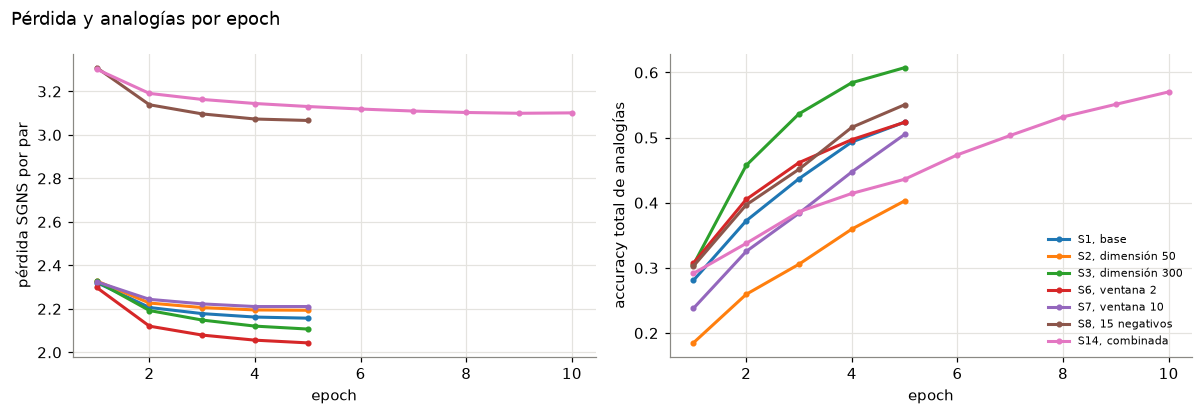

In [22]:
mostrar = ["S1", "S2", "S3", "S6", "S7", "S8", MEJOR]
mostrar = list(dict.fromkeys(mostrar))
paleta = sns.color_palette("tab10", len(mostrar))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for color, nombre in zip(paleta, mostrar):
    r = next(x for x in REGISTROS if x["nombre"] == nombre)
    ep = np.arange(1, len(r["hist"]["loss"]) + 1)
    etiqueta = f"{nombre}, {ETIQUETA[nombre]}"
    axes[0].plot(ep, r["hist"]["loss"], color=color, marker="o", ms=3, label=etiqueta)
    axes[1].plot(ep, r["hist"]["total"], color=color, marker="o", ms=3, label=etiqueta)
axes[0].set_ylabel("pérdida SGNS por par")
axes[1].set_ylabel("accuracy total de analogías")
for ax in axes:
    ax.set_xlabel("epoch")
axes[1].legend(frameon=False, fontsize=7)
fig.suptitle("Pérdida y analogías por epoch", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("figuras/curvas_sgns.png")
plt.show()

Una pérdida más baja no implica mejores embeddings. Entre configuraciones la pérdida no es comparable: S8 y S14, con 15 negativos, tienen la pérdida más alta, cerca de 3.1, porque suman tres veces más términos negativos, y aun así tienen los mejores accuracy de dimensión 100. S6, con ventana 2, tiene la pérdida más baja, 2.04, porque predecir vecinos inmediatos es más fácil, pero no supera a S1. Dentro de una misma corrida la pérdida se estanca mientras las analogías siguen mejorando: en S13 la pérdida baja solo de 2.162 a 2.138 entre las epochs 5 y 10, mientras el accuracy sube de 43.3 % a 54.7 %. La pérdida mide qué tan bien se distinguen contextos reales de negativos, no la geometría que piden las analogías.

### 4.4 Word2Vec de gensim

Se entrena skip-gram de gensim sobre exactamente los mismos párrafos tokenizados, con el mismo min_count y los hiperparámetros equivalentes a la mejor configuración. El corpus se escribe en un archivo con un párrafo por línea y se lee con LineSentence. En una prueba previa el modo corpus_file de gensim dio analogías mucho peores con los mismos hiperparámetros, por lo que se usa el modo iterable. gensim corre en CPU con 8 hilos, uno por núcleo físico.

In [23]:
n_tok_mejor = REG_MEJOR["tokens"]
n_parrafos = int(len(largos) * CFG_MEJOR["fraccion"])
with open("datos/corpus.txt", "w", encoding="utf-8") as f:
    ini = 0
    for L in largos[:n_parrafos]:
        f.write(" ".join(PALABRAS[IDS[ini:ini + L]]) + "\n")
        ini += L

class Registro(CallbackAny2Vec):
    def __init__(self):
        self.hist = {k: [] for k in ["loss", "sem", "sin", "total", "ws353", "vecinos", "t_epoch", "pares"]}
        self.loss_previa = 0.0

    def on_epoch_begin(self, modelo):
        self.t0 = time.perf_counter()

    def on_epoch_end(self, modelo):
        t_epoch = time.perf_counter() - self.t0
        loss = modelo.get_latest_training_loss()
        registrar_epoch(self.hist, modelo.wv, loss - self.loss_previa, t_epoch, 0)
        self.loss_previa = loss
        h = self.hist
        print(f"[gensim] epoch {len(h['loss'])} | loss {h['loss'][-1]:,.0f} | sem {h['sem'][-1]:.4f} | sin {h['sin'][-1]:.4f} | "
              f"total {h['total'][-1]:.4f} | WS353 {h['ws353'][-1]:.4f} | {t_epoch:.1f} s")

registro_w2v = Registro()
t0 = time.perf_counter()
w2v = Word2Vec(LineSentence("datos/corpus.txt"), vector_size=CFG_MEJOR["dim"], window=CFG_MEJOR["ventana"],
               negative=CFG_MEJOR["negativos"], sample=CFG_MEJOR["t"], min_count=CFG_MEJOR["min_count"], sg=1,
               alpha=CFG_MEJOR["lr"], min_alpha=CFG_MEJOR["lr"] * 1e-4, epochs=CFG_MEJOR["epochs"],
               workers=8, seed=SEED, compute_loss=True, callbacks=[registro_w2v])
t_w2v_total = time.perf_counter() - t0
w2v_kv = w2v.wv
print(f"Vocabulario gensim {len(w2v_kv):,} | propio {len(sgns):,} | mismo vocabulario: {set(w2v_kv.index_to_key) == set(sgns.index_to_key)}")
print(f"Tiempo total incluyendo vocabulario y evaluaciones: {t_w2v_total:.0f} s | solo entrenamiento: {sum(registro_w2v.hist['t_epoch']):.0f} s")
for w, l in registro_w2v.hist["vecinos"][-1].items():
    print(f"{w}: {', '.join(l)}")

[gensim] epoch 1 | loss 68,854,368 | sem 0.2064 | sin 0.2869 | total 0.2610 | WS353 0.6065 | 84.4 s


[gensim] epoch 2 | loss 15,204,976 | sem 0.2748 | sin 0.3508 | total 0.3264 | WS353 0.6405 | 84.9 s


[gensim] epoch 3 | loss 14,885,368 | sem 0.2909 | sin 0.3874 | total 0.3564 | WS353 0.6501 | 84.7 s


[gensim] epoch 4 | loss 14,338,920 | sem 0.3349 | sin 0.4171 | total 0.3906 | WS353 0.6527 | 86.0 s


[gensim] epoch 5 | loss 13,789,152 | sem 0.3770 | sin 0.4584 | total 0.4322 | WS353 0.6578 | 84.9 s


[gensim] epoch 6 | loss 7,144,944 | sem 0.3847 | sin 0.5020 | total 0.4643 | WS353 0.6568 | 85.6 s


[gensim] epoch 7 | loss 0 | sem 0.4120 | sin 0.5324 | total 0.4937 | WS353 0.6704 | 86.5 s


[gensim] epoch 8 | loss 0 | sem 0.4598 | sin 0.5623 | total 0.5293 | WS353 0.6765 | 86.1 s


[gensim] epoch 9 | loss 0 | sem 0.4743 | sin 0.5849 | total 0.5493 | WS353 0.6757 | 87.6 s


[gensim] epoch 10 | loss 0 | sem 0.4960 | sin 0.5952 | total 0.5633 | WS353 0.6815 | 81.5 s
Vocabulario gensim 86,083 | propio 86,083 | mismo vocabulario: True
Tiempo total incluyendo vocabulario y evaluaciones: 872 s | solo entrenamiento: 852 s
king: harthacnut, vi, prince, iv, monarch
france: spain, belgium, italy, portugal, luxembourg
computer: computers, software, simulation, computing, programmable
good: bad, excellent, decent, luck, perfect
january: december, february, march, november, april
run: running, ran, runs, inside-the-park, 6-yard


gensim llega a 56.3 % de accuracy total y 0.682 en WordSim-353, frente a 57.0 % y 0.681 de la implementación propia, con curvas por epoch casi iguales y vecinos muy parecidos: para france ambos dan spain, belgium, italy y luxembourg, y para run ambos dan running, runs y ran. El vocabulario es idéntico, 86,083 palabras. gensim tardó 85 s por epoch en 8 núcleos y la versión propia 64.5 s en la GPU. La pérdida de gensim no es comparable: la acumula en float32, deja de crecer cerca de 134 millones y desde la epoch 7 la diferencia por epoch es 0, una limitación conocida de compute_loss.

## 5. Verificación de la aritmética vectorial

### 5.1 Analogías individuales

La función analogia resuelve a es a b como c es a ? con 3CosAdd: normaliza los vectores, calcula b − a + c, lo normaliza y ordena todo el vocabulario por similitud coseno con ese vector, excluyendo a, b y c. Se verifica contra most_similar de gensim.

In [24]:
MODELOS = {"sgns": sgns, "gensim": w2v_kv, "glove": glove}

def similitudes_analogia(kv, a, b, c, excluir=True):
    E = kv.get_normed_vectors()
    i = kv.key_to_index
    d = E[i[b]] - E[i[a]] + E[i[c]]
    sims = E @ (d / np.linalg.norm(d))
    if excluir:
        sims[[i[a], i[b], i[c]]] = -np.inf
    return sims

def analogia(kv, a, b, c, k=5, excluir=True):
    sims = similitudes_analogia(kv, a, b, c, excluir)
    top = np.argsort(-sims)[:k]
    return [(kv.index_to_key[j], round(float(sims[j]), 4)) for j in top]

for nombre, kv in MODELOS.items():
    propio = analogia(kv, "man", "king", "woman")
    referencia = [(w, round(s, 4)) for w, s in kv.most_similar(positive=["king", "woman"], negative=["man"], topn=5)]
    print(f"{NOMBRE[nombre]:16s} propio: {propio}")
    print(f"{'':16s} gensim: {referencia} | coinciden: {propio == referencia}")

SGNS propio      propio: [('queen', 0.7376), ('regnant', 0.7101), ('tvrtko', 0.6843), ('princess', 0.6826), ('monarch', 0.6675)]
                 gensim: [('queen', 0.7376), ('regnant', 0.7101), ('tvrtko', 0.6843), ('princess', 0.6826), ('monarch', 0.6675)] | coinciden: True
Word2Vec gensim  propio: [('queen', 0.7357), ('regnant', 0.7231), ('jagiellon', 0.6806), ('monarch', 0.6681), ('consort', 0.6657)]
                 gensim: [('queen', 0.7357), ('regnant', 0.7231), ('jagiellon', 0.6806), ('monarch', 0.6681), ('consort', 0.6657)] | coinciden: True


GloVe            propio: [('queen', 0.7699), ('monarch', 0.6843), ('throne', 0.6756), ('daughter', 0.6595), ('princess', 0.6521)]
                 gensim: [('queen', 0.7699), ('monarch', 0.6843), ('throne', 0.6756), ('daughter', 0.6595), ('princess', 0.6521)] | coinciden: True


In [25]:
MIS_ANALOGIAS = [
    ("género", "man", "woman", "king", "queen"),
    ("género", "brother", "sister", "son", "daughter"),
    ("género", "actor", "actress", "prince", "princess"),
    ("país-capital", "france", "paris", "japan", "tokyo"),
    ("país-capital", "germany", "berlin", "italy", "rome"),
    ("país-capital", "spain", "madrid", "russia", "moscow"),
    ("país-gentilicio", "france", "french", "germany", "german"),
    ("país-gentilicio", "china", "chinese", "mexico", "mexican"),
    ("país-gentilicio", "canada", "canadian", "australia", "australian"),
    ("comparativo", "good", "better", "bad", "worse"),
    ("comparativo", "big", "bigger", "small", "smaller"),
    ("superlativo", "fast", "fastest", "strong", "strongest"),
    ("tiempo verbal", "go", "went", "take", "took"),
    ("tiempo verbal", "write", "wrote", "speak", "spoke"),
    ("tiempo verbal", "play", "playing", "swim", "swimming"),
    ("plural", "car", "cars", "child", "children"),
    ("plural", "city", "cities", "country", "countries"),
    ("plural", "dog", "dogs", "woman", "women"),
]

filas = []
for tipo, a, b, c, esperado in MIS_ANALOGIAS:
    for nombre, kv in MODELOS.items():
        sims = similitudes_analogia(kv, a, b, c)
        sims_sin = similitudes_analogia(kv, a, b, c, excluir=False)
        primera = kv.index_to_key[int(np.argmax(sims_sin))]
        filas.append({"tipo": tipo, "analogía": f"{a}:{b} :: {c}:?", "esperada": esperado, "modelo": NOMBRE[nombre],
                      "top-5": ", ".join(f"{w} {s:.2f}" for w, s in analogia(kv, a, b, c)),
                      "rango": int((sims > sims[kv.key_to_index[esperado]]).sum()) + 1,
                      "coseno esperada": round(float(sims[kv.key_to_index[esperado]]), 3),
                      "primera sin excluir": primera,
                      "papel de la primera": {a: "a", b: "b", c: "c", esperado: "esperada"}.get(primera, "otra"),
                      "rango esperada sin excluir": int((sims_sin > sims_sin[kv.key_to_index[esperado]]).sum()) + 1})
tabla_analogias = pd.DataFrame(filas)
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(tabla_analogias)
tabla_analogias.to_csv("resultados/analogias_propias.csv", index=False, encoding="utf-8")

,tipo,analogía,esperada,modelo,top-5,rango,coseno esperada,primera sin excluir,papel de la primera,rango esperada sin excluir
0,género,man:woman :: king:?,queen,SGNS propio,"queen 0.74, regnant 0.71, tvrtko 0.68, princess 0.68, monarch 0.67",1,0.738,king,c,2
1,género,man:woman :: king:?,queen,Word2Vec gensim,"queen 0.74, regnant 0.72, jagiellon 0.68, monarch 0.67, consort 0.67",1,0.736,king,c,2
2,género,man:woman :: king:?,queen,GloVe,"queen 0.77, monarch 0.68, throne 0.68, daughter 0.66, princess 0.65",1,0.770,king,c,2
3,género,brother:sister :: son:?,daughter,SGNS propio,"daughter 0.82, sisters 0.75, wife 0.75, daughters 0.75, mother 0.74",1,0.824,sister,b,2
4,género,brother:sister :: son:?,daughter,Word2Vec gensim,"daughter 0.82, granddaughter 0.76, wife 0.76, half-sister 0.75, sisters 0.74",1,0.823,sister,b,2
5,género,brother:sister :: son:?,daughter,GloVe,"daughter 0.89, mother 0.85, wife 0.81, niece 0.78, daughters 0.78",1,0.895,sister,b,2
6,género,actor:actress :: prince:?,princess,SGNS propio,"princess 0.84, mecklenburg-strelitz 0.75, duchess 0.74, queen 0.74, melita 0.73",1,0.843,prince,c,2
7,género,actor:actress :: prince:?,princess,Word2Vec gensim,"princess 0.85, queen 0.76, duchess 0.76, mecklenburg-strelitz 0.75, louise 0.72",1,0.849,prince,c,2
8,género,actor:actress :: prince:?,princess,GloVe,"princess 0.82, queen 0.72, duchess 0.68, daughter 0.67, niece 0.63",1,0.824,prince,c,2
9,país-capital,france:paris :: japan:?,tokyo,SGNS propio,"tokyo 0.86, yokohama 0.78, osaka 0.77, shanghai 0.69, fukuoka 0.68",1,0.861,tokyo,esperada,1


In [26]:
resumen_propias = tabla_analogias.groupby("modelo").agg(
    aciertos_top1=("rango", lambda r: int((r == 1).sum())), aciertos_top5=("rango", lambda r: int((r <= 5).sum())),
    rango_mediano=("rango", "median"), coseno_medio=("coseno esperada", "mean"))
display(resumen_propias)
display(pd.crosstab(tabla_analogias["modelo"], tabla_analogias["papel de la primera"]))

,aciertos_top1,aciertos_top5,rango_mediano,coseno_medio
modelo,,,,
GloVe,15,18,1.0,0.844667
SGNS propio,16,18,1.0,0.783722
Word2Vec gensim,16,18,1.0,0.775833


papel de la primera,b,c,esperada,otra
modelo,,,,
GloVe,1,7,8,2
SGNS propio,3,7,7,1
Word2Vec gensim,3,7,7,1


La función propia coincide exactamente con most_similar de gensim en palabras y similitudes para los tres modelos. En las 18 analogías propias, SGNS y gensim aciertan 16 en el primer lugar y GloVe 15. Los tres tienen las 18 respuestas dentro del top 5. Los fallos son germany:berlin :: italy:?, donde SGNS y gensim responden vienna, una capital germanohablante, GloVe responde venice y rome queda segunda o cuarta, y big:bigger :: small:?, donde los tres modelos responden larger antes que smaller, porque el vector de big está muy cerca de large. GloVe falla además dog:dogs :: woman:?, con pregnant y men antes que women. La similitud coseno con la respuesta correcta está entre 0.66 y 0.96, nunca cerca de 1.

Sin excluir las palabras de la consulta, la respuesta esperada solo queda primera en 7 de 18 analogías con SGNS y gensim y en 8 con GloVe, las de país-capital, gentilicio y tiempo verbal, donde el desplazamiento es grande. En las demás la primera palabra casi siempre es c, por ejemplo king para man:woman :: king:?, o b, por ejemplo sister, y la respuesta correcta queda segunda. Solo en big:bigger :: small:? y en la de Italia con GloVe gana otra palabra. Esto muestra que b − a + c cae mucho más cerca de c que de la respuesta: la diferencia b − a es pequeña frente al vector de c y la aritmética solo mueve el punto un poco en la dirección correcta. Excluir las palabras de la consulta es lo que convierte ese pequeño desplazamiento en un acierto.

### 5.2 Evaluación sistemática

Para que los tres modelos respondan exactamente las mismas preguntas se usa un vocabulario compartido: las 30,000 palabras más frecuentes del corpus que existen en los tres modelos. SGNS y gensim tienen el mismo vocabulario, así que basta con filtrar por GloVe.

In [27]:
VOCAB_COMUN = [w for w in PALABRAS[:len(sgns)] if w in glove.key_to_index and w in w2v_kv.key_to_index][:30000]
print(f"Vocabulario compartido: {len(VOCAB_COMUN):,} palabras, última en rango {list(PALABRAS).index(VOCAB_COMUN[-1]) + 1:,} del corpus")

RES_ANALOGIAS = {(m, metodo): evaluar_analogias(kv, VOCAB_COMUN, metodo) for m, kv in MODELOS.items() for metodo in ["add", "mul"]}
filas = []
for cat in CATEGORIAS:
    r0 = RES_ANALOGIAS[("sgns", "add")][cat]
    fila = {"categoría": cat, "tipo": "semántica" if cat in SEMANTICAS else "sintáctica",
            "evaluadas": r0["evaluadas"], "total": r0["total"], "cobertura": round(r0["evaluadas"] / r0["total"], 3)}
    for (m, metodo), res in RES_ANALOGIAS.items():
        fila[f"{m} {metodo}"] = round(res[cat]["aciertos"] / max(res[cat]["evaluadas"], 1), 3)
    filas.append(fila)
for nombre, cats in [("semánticas", SEMANTICAS), ("sintácticas", CATEGORIAS[5:]), ("total", CATEGORIAS)]:
    ev = sum(RES_ANALOGIAS[("sgns", "add")][c]["evaluadas"] for c in cats)
    tot = sum(RES_ANALOGIAS[("sgns", "add")][c]["total"] for c in cats)
    fila = {"categoría": nombre, "tipo": "", "evaluadas": ev, "total": tot, "cobertura": round(ev / tot, 3)}
    for (m, metodo), res in RES_ANALOGIAS.items():
        fila[f"{m} {metodo}"] = round(sum(res[c]["aciertos"] for c in cats) / ev, 3)
    filas.append(fila)
tabla_categorias = pd.DataFrame(filas)
display(tabla_categorias)
tabla_categorias.to_csv("resultados/analogias_por_categoria.csv", index=False, encoding="utf-8")

Vocabulario compartido: 30,000 palabras, última en rango 30,026 del corpus


,categoría,tipo,evaluadas,total,cobertura,sgns add,sgns mul,gensim add,gensim mul,glove add,glove mul
0,capital-common-countries,semántica,462,506,0.913,0.727,0.693,0.682,0.673,0.937,0.920
1,capital-world,semántica,1213,4524,0.268,0.600,0.565,0.585,0.556,0.892,0.862
2,currency,semántica,88,866,0.102,0.000,0.011,0.000,0.011,0.045,0.034
3,city-in-state,semántica,1810,2467,0.734,0.383,0.362,0.388,0.368,0.306,0.269
4,family,semántica,342,506,0.676,0.637,0.605,0.629,0.599,0.880,0.868
5,gram1-adjective-to-adverb,sintáctica,756,992,0.762,0.243,0.212,0.228,0.192,0.295,0.294
6,gram2-opposite,sintáctica,342,812,0.421,0.246,0.178,0.234,0.155,0.254,0.219
7,gram3-comparative,sintáctica,1260,1332,0.946,0.698,0.686,0.698,0.680,0.800,0.780
8,gram4-superlative,sintáctica,702,1122,0.626,0.405,0.403,0.415,0.423,0.608,0.613
9,gram5-present-participle,sintáctica,870,1056,0.824,0.541,0.516,0.513,0.482,0.721,0.715


Con el vocabulario compartido se evalúan 12,170 de las 19,544 preguntas, una cobertura de 62.3 %: 44.1 % de las semánticas y 77.3 % de las sintácticas. Las que faltan contienen ciudades, monedas y países poco frecuentes que no están entre las 30,000 palabras más comunes. Con 3CosAdd, SGNS obtiene 57.0 % en total, 50.5 % en semánticas y 60.1 % en sintácticas. Word2Vec de gensim obtiene 56.3 %, 49.6 % y 59.5 %, y GloVe 65.6 %, 60.6 % y 68.0 %. 3CosMul queda entre 1 y 3 puntos por debajo de 3CosAdd en los tres modelos.

Las categorías que mejor funcionan son nationality-adjective, con 88.2 % en SGNS, capital-common-countries, past-tense y comparative. Las peores son currency, con 0 %, adjective-to-adverb y opposite, alrededor de 24 %. Los opuestos fallan porque un antónimo como unacceptable aparece en los mismos contextos que acceptable y el modelo no separa bien la negación. GloVe supera a SGNS sobre todo en semánticas como capital-world, 89.2 % frente a 60.0 %, porque necesita haber visto muchos datos de cada país. SGNS supera a GloVe en city-in-state, 38.3 % frente a 30.6 %, y en past-tense, 72.3 % frente a 58.8 %, relaciones muy frecuentes en Wikipedia.

### 5.3 Paralelismo de los vectores diferencia

Si la aritmética fuera exacta, todos los vectores diferencia de una relación, como king − queen y man − woman, serían paralelos. Para cada categoría se toman los pares únicos de palabras de questions-words.txt dentro del vocabulario compartido, se calcula b − a con vectores normalizados y se promedia la similitud coseno entre todos los pares de diferencias. Como referencia se usan 500 pares de palabras al azar del mismo vocabulario.

In [28]:
def paralelismo(kv, pares):
    E = kv.get_normed_vectors()
    i = kv.key_to_index
    D = np.array([E[i[b]] - E[i[a]] for a, b in pares])
    D /= np.linalg.norm(D, axis=1, keepdims=True)
    S = D @ D.T
    n = len(D)
    return (S.sum() - n) / (n * (n - 1))

comun = set(VOCAB_COMUN)
PARES = {}
for cat, preguntas in ANALOGIAS.items():
    pares = {(p[0], p[1]) for p in preguntas} | {(p[2], p[3]) for p in preguntas}
    PARES[cat] = sorted(p for p in pares if p[0] in comun and p[1] in comun)
rng = np.random.default_rng(SEED)
PARES["al azar"] = [tuple(rng.choice(VOCAB_COMUN, 2, replace=False)) for _ in range(500)]
PARES["género clásico"] = [("man", "woman"), ("king", "queen"), ("boy", "girl"), ("he", "she"), ("father", "mother"),
                           ("brother", "sister"), ("husband", "wife"), ("uncle", "aunt"), ("son", "daughter"), ("prince", "princess")]

tabla_paralelismo = pd.DataFrame([{"categoría": cat, "pares": len(p), **{m: round(paralelismo(kv, p), 3) for m, kv in MODELOS.items()}}
                                  for cat, p in PARES.items()])
PARALELISMO_MEDIO = {m: tabla_paralelismo.loc[tabla_paralelismo["categoría"].isin(CATEGORIAS), m].mean() for m in MODELOS}
display(tabla_paralelismo)
print("Promedio sobre las 14 categorías:", {m: round(v, 3) for m, v in PARALELISMO_MEDIO.items()})

,categoría,pares,sgns,gensim,glove
0,capital-common-countries,22,0.392,0.386,0.586
1,capital-world,60,0.311,0.313,0.561
2,currency,10,0.221,0.213,0.260
3,city-in-state,58,0.204,0.208,0.336
4,family,19,0.315,0.317,0.507
5,gram1-adjective-to-adverb,28,0.164,0.158,0.282
6,gram2-opposite,19,0.106,0.108,0.227
7,gram3-comparative,36,0.359,0.353,0.422
8,gram4-superlative,27,0.309,0.319,0.465
9,gram5-present-participle,30,0.220,0.220,0.319


Promedio sobre las 14 categorías: {'sgns': np.float32(0.28), 'gensim': np.float32(0.278), 'glove': np.float32(0.405)}


Los vectores diferencia de una misma relación apuntan en direcciones parecidas, pero están lejos de ser paralelos. El coseno promedio sobre las 14 categorías es 0.280 en SGNS, 0.278 en gensim y 0.405 en GloVe, frente a 0.000 para pares al azar. Un coseno de 0.28 equivale a un ángulo de unos 74 grados. La relación más consistente es nationality-adjective, con 0.55 en SGNS y 0.75 en GloVe, la misma categoría con mejor accuracy. Las menos consistentes son opposite y adjective-to-adverb, con 0.11 y 0.16, también las de peor accuracy. Para el género clásico, man-woman, king-queen y similares, el coseno es 0.32 en SGNS y 0.56 en GloVe. Hay una relación directa: cuanto más paralelas son las diferencias de una categoría, mejor funciona la aritmética en ella.

### 5.4 Visualización con t-SNE

Se proyectan alrededor de 500 palabras de 10 grupos temáticos con el mejor modelo SGNS. Los países y capitales salen de questions-words.txt y el resto de listas propias.

483 palabras en 10 grupos


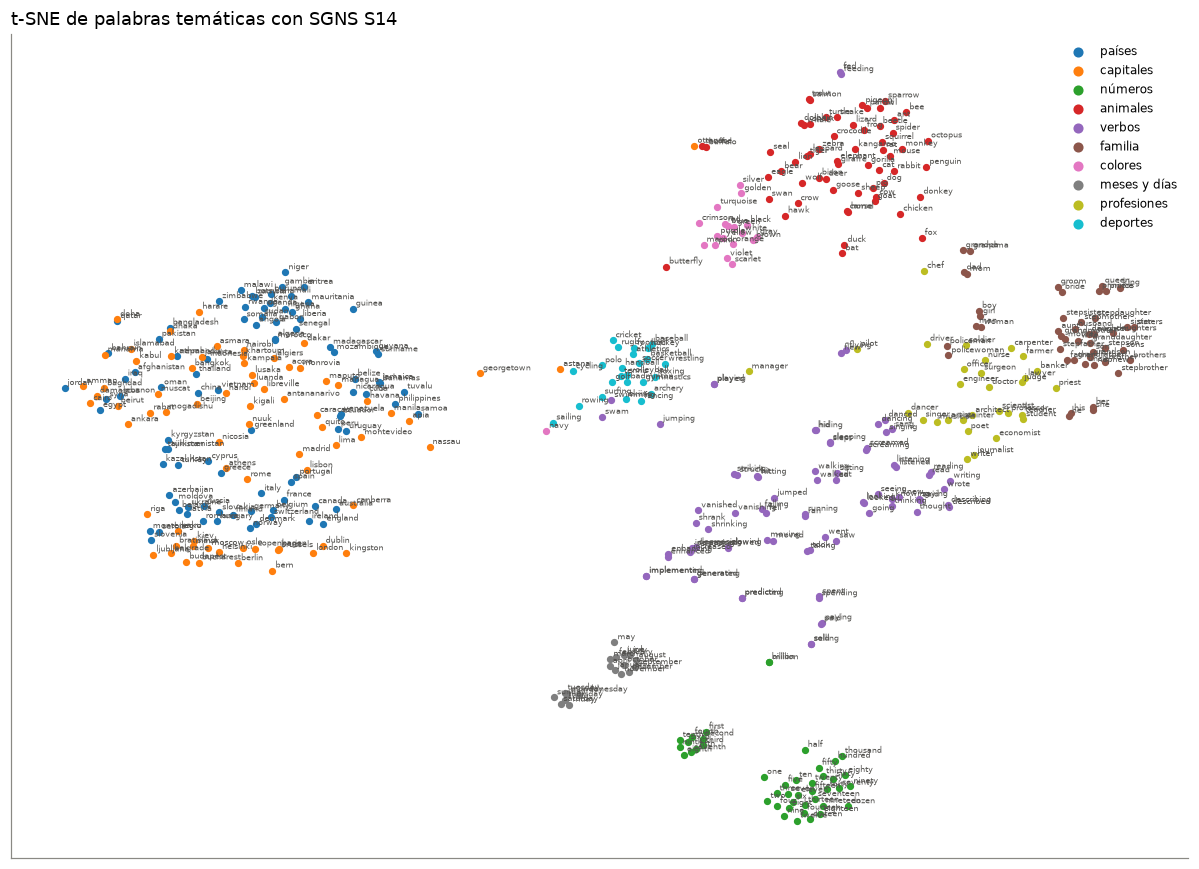

In [29]:
mundo = ANALOGIAS["capital-world"] + ANALOGIAS["capital-common-countries"]
GRUPOS = {
    "países": list(dict.fromkeys(p[1] for p in mundo))[:90],
    "capitales": list(dict.fromkeys(p[0] for p in mundo))[:90],
    "números": ("one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen "
                "seventeen eighteen nineteen twenty thirty forty fifty sixty seventy eighty ninety hundred thousand "
                "million billion first second third fourth fifth sixth seventh eighth ninth tenth dozen half").split(),
    "animales": ("dog cat horse cow pig sheep goat chicken duck goose rabbit mouse rat squirrel deer bear wolf fox lion "
                 "tiger leopard elephant giraffe zebra monkey gorilla camel kangaroo whale dolphin shark seal octopus "
                 "salmon trout eagle hawk owl parrot crow pigeon sparrow swan penguin snake lizard crocodile turtle frog "
                 "spider ant bee butterfly beetle bat donkey buffalo bison moose").split(),
    "verbos": list(dict.fromkeys(w for p in ANALOGIAS["gram7-past-tense"] for w in p))[:80],
    "familia": list(dict.fromkeys(w for p in ANALOGIAS["family"] for w in p)),
    "colores": "red blue green yellow orange purple pink brown black white gray violet crimson scarlet turquoise maroon navy golden silver".split(),
    "meses y días": ("january february march april may june july august september october november december "
                     "monday tuesday wednesday thursday friday saturday sunday").split(),
    "profesiones": ("doctor nurse teacher lawyer engineer scientist farmer soldier pilot driver chef artist musician "
                    "writer poet singer dancer painter journalist judge priest officer professor student manager "
                    "banker carpenter architect surgeon economist").split(),
    "deportes": ("football soccer basketball baseball tennis golf hockey cricket rugby boxing wrestling swimming cycling "
                 "volleyball skiing athletics badminton handball polo surfing rowing sailing fencing archery gymnastics").split(),
}
palabras_tsne, grupos_tsne, vistas = [], [], set()
for g, lista in GRUPOS.items():
    for w in lista:
        if w in sgns.key_to_index and w not in vistas:
            palabras_tsne.append(w)
            grupos_tsne.append(g)
            vistas.add(w)
print(f"{len(palabras_tsne)} palabras en {len(GRUPOS)} grupos")

coords = TSNE(n_components=2, perplexity=30, init="pca", metric="cosine", random_state=SEED).fit_transform(sgns[palabras_tsne])
paleta = dict(zip(GRUPOS, sns.color_palette("tab10", len(GRUPOS))))
fig, ax = plt.subplots(figsize=(11, 8))
for g in GRUPOS:
    m = np.array(grupos_tsne) == g
    ax.scatter(coords[m, 0], coords[m, 1], s=14, color=paleta[g], label=g)
for (x, y), w in zip(coords, palabras_tsne):
    ax.annotate(w, (x, y), fontsize=5.5, color="#52514e", xytext=(2, 2), textcoords="offset points")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(frameon=False, fontsize=8, markerscale=1.5, loc="best")
ax.set_title(f"t-SNE de palabras temáticas con SGNS {MEJOR}", loc="left")
plt.tight_layout()
plt.savefig("figuras/tsne.png")
plt.show()

Se proyectaron 483 palabras y se forman los grupos esperados. Números, meses y días, animales, colores, deportes, familia y profesiones forman nubes separadas. Dentro de los números, ordinales y cardinales forman dos subgrupos, y días y meses aparecen juntos pero separados. Países y capitales comparten una región grande y dentro de ella se ordenan por geografía: África, Medio Oriente y Asia, Europa del este, Europa occidental y América aparecen en zonas distintas, con la mayoría de las capitales cerca de su país. Los verbos forman la región más dispersa, organizada por pares de gerundio y pasado como walking y walked, y algunos se acercan a otros grupos, como swam junto a los deportes. Las profesiones aparecen cerca de la familia porque ambas se refieren a personas, y algunas palabras ambiguas se salen de su grupo, como navy, que es un color pero se usa sobre todo como marina y queda junto a los deportes.

## 6. Pipeline end-to-end: clasificación de AG News

### 6.1 Preparación de los datos

Se usan el mismo normalizador y el mismo tokenizador de la sección 2. El 10 % del entrenamiento se separa de forma estratificada como validación y el test oficial se usa una sola vez al final. El vocabulario del clasificador son las palabras del entrenamiento que aparecen al menos dos veces. Las demás se descartan. Cada noticia se convierte en una fila de IDs rellenada con ceros hasta 100 tokens.

In [30]:
ETIQUETAS = news["train"].features["label"].names
tok_train = [tokenizar(t) for t in news["train"]["text"]]
tok_test = [tokenizar(t) for t in news["test"]["text"]]
y_train_full = np.array(news["train"]["label"])
y_test = np.array(news["test"]["label"])
idx_tr, idx_val = train_test_split(np.arange(len(y_train_full)), test_size=0.10, stratify=y_train_full, random_state=SEED)

print("Clases:", ETIQUETAS)
print(f"entrenamiento: {len(idx_tr):,} | validación: {len(idx_val):,} | test: {len(y_test):,}")
print("Por clase en validación:", np.bincount(y_train_full[idx_val]))
largos_ag = np.array([len(t) for t in tok_train])
print(f"Tokens por noticia: media {largos_ag.mean():.1f} | percentil 99 {np.percentile(largos_ag, 99):.0f} | máximo {largos_ag.max()}")

todos = [w for doc in tok_train + tok_test for w in doc]
tipos = set(todos)
OOV = {}
for m, kv in MODELOS.items():
    OOV[m] = 100 * sum(w not in kv.key_to_index for w in todos) / len(todos)
    print(f"{NOMBRE[m]:16s}: {OOV[m]:.2f} % de tokens y {100 * sum(w not in kv.key_to_index for w in tipos) / len(tipos):.1f} % de palabras distintas fuera del vocabulario")

Clases: ['World', 'Sports', 'Business', 'Sci/Tech']
entrenamiento: 108,000 | validación: 12,000 | test: 7,600
Por clase en validación: [3000 3000 3000 3000]
Tokens por noticia: media 37.7 | percentil 99 70 | máximo 181


SGNS propio     : 3.77 % de tokens y 51.7 % de palabras distintas fuera del vocabulario


Word2Vec gensim : 3.77 % de tokens y 51.7 % de palabras distintas fuera del vocabulario


GloVe           : 0.92 % de tokens y 25.0 % de palabras distintas fuera del vocabulario


In [31]:
conteo_ag = Counter(w for i in idx_tr for w in tok_train[i])
VOCAB_AG = ["<pad>"] + [w for w, c in conteo_ag.most_common() if c >= 2]
W2I_AG = {w: i for i, w in enumerate(VOCAB_AG)}
LARGO_MAX = 100

def a_tensor(docs):
    X = np.zeros((len(docs), LARGO_MAX), dtype=np.int64)
    for i, doc in enumerate(docs):
        ids = [W2I_AG[w] for w in doc if w in W2I_AG][:LARGO_MAX]
        X[i, :len(ids)] = ids
    return torch.from_numpy(X).to(DEVICE)

X_train_full, X_test = a_tensor(tok_train), a_tensor(tok_test)
Y_train_full = torch.from_numpy(y_train_full).to(DEVICE)
print(f"Vocabulario del clasificador: {len(VOCAB_AG):,} | matriz de entrenamiento {tuple(X_train_full.shape)}")

def matriz_inicial(kv):
    fijar_semilla()
    E = np.random.normal(0, kv.vectors.std(), (len(VOCAB_AG), kv.vector_size)).astype(np.float32)
    encontradas = 0
    for i, w in enumerate(VOCAB_AG):
        if w in kv.key_to_index:
            E[i] = kv[w]
            encontradas += 1
    E[0] = 0
    return torch.from_numpy(E), encontradas / len(VOCAB_AG)

PESOS = {}
for m, kv in MODELOS.items():
    PESOS[m], cob = matriz_inicial(kv)
    print(f"{NOMBRE[m]:16s}: {100 * cob:.1f} % del vocabulario del clasificador tiene vector preentrenado")

Vocabulario del clasificador: 49,454 | matriz de entrenamiento (120000, 100)
SGNS propio     : 67.0 % del vocabulario del clasificador tiene vector preentrenado


Word2Vec gensim : 67.0 % del vocabulario del clasificador tiene vector preentrenado


GloVe           : 89.3 % del vocabulario del clasificador tiene vector preentrenado


### 6.2 Baseline TF-IDF con regresión logística

Se usan unigramas y bigramas con frecuencia de documento mínima de 2 y tf sublineal. El parámetro C se elige con el F1 macro de validación.

In [32]:
def metricas(y, pred):
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "precision": p, "recall": r, "f1": f1}

def entrenar_tfidf(idx, C):
    vect = TfidfVectorizer(tokenizer=lambda d: d, preprocessor=lambda d: d, token_pattern=None, lowercase=False,
                           ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    X = vect.fit_transform([tok_train[i] for i in idx])
    clf = LogisticRegression(C=C, max_iter=2000).fit(X, y_train_full[idx])
    return vect, clf

RES_CLF = {}
mejor_tfidf = None
for C in [1, 10]:
    t0 = time.perf_counter()
    vect, clf = entrenar_tfidf(idx_tr, C)
    t_tfidf = time.perf_counter() - t0
    val = metricas(y_train_full[idx_val], clf.predict(vect.transform([tok_train[i] for i in idx_val])))
    print(f"C={C}: val F1 {val['f1']:.4f} | {t_tfidf:.1f} s | {len(vect.vocabulary_):,} n-gramas")
    if mejor_tfidf is None or val["f1"] > mejor_tfidf[2]["f1"]:
        mejor_tfidf = (vect, clf, val, t_tfidf, C)
vect, clf, val, t_tfidf, C_TFIDF = mejor_tfidf
n_param = clf.coef_.size + clf.intercept_.size
RES_CLF["tfidf"] = {"modelo": "TF-IDF + regresión logística", "init": "tfidf", "val": val, "params": n_param,
                    "entrenables": n_param, "tiempo": t_tfidf, "hist": None, "epoch": None}

C=1: val F1 0.9223 | 20.4 s | 424,029 n-gramas


C=10: val F1 0.9246 | 31.2 s | 424,029 n-gramas


### 6.3 EmbeddingBag con MLP

El clasificador promedia los vectores de las palabras con nn.EmbeddingBag en modo mean, ignorando el relleno con padding_idx, y aplica un MLP de una capa oculta de 256 neuronas con ReLU y dropout de 0.3. La versión aleatoria parte de la inicialización normal de PyTorch. Las versiones preentrenadas copian el vector de cada palabra disponible y para las demás usan una normal con la desviación de la matriz preentrenada. Se entrena con Adam, learning rate 0.001, lotes de 256 y 10 epochs, y se guarda la epoch con mejor F1 macro de validación.

In [33]:
class Clasificador(nn.Module):
    def __init__(self, n_palabras, dim=100, pesos=None, congelar=False, oculta=256, n_clases=4):
        super().__init__()
        if pesos is None:
            self.emb = nn.EmbeddingBag(n_palabras, dim, mode="mean", padding_idx=0)
        else:
            self.emb = nn.EmbeddingBag.from_pretrained(pesos, freeze=congelar, mode="mean", padding_idx=0)
        self.mlp = nn.Sequential(nn.Linear(dim, oculta), nn.ReLU(), nn.Dropout(0.3), nn.Linear(oculta, n_clases))

    def forward(self, x):
        return self.mlp(self.emb(x))

@torch.no_grad()
def evaluar_clf(modelo, X, y):
    modelo.eval()
    logits = torch.cat([modelo(X[i:i + 4096]) for i in range(0, len(X), 4096)])
    pred = logits.argmax(1).cpu().numpy()
    return {"loss": F.cross_entropy(logits, torch.as_tensor(y, device=DEVICE)).item(), **metricas(y, pred), "pred": pred}

def entrenar_clf(init, congelar, idx=idx_tr, epochs=10, lr=1e-3, batch=256, verbose=True):
    fijar_semilla()
    pesos = None if init == "aleatoria" else PESOS[init].clone()
    modelo = Clasificador(len(VOCAB_AG), pesos=pesos, congelar=congelar).to(DEVICE)
    opt = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=lr)
    idx_t = torch.as_tensor(idx, device=DEVICE)
    hist = {"train_loss": [], "val_loss": [], "val_f1": []}
    mejor_f1, mejor_estado, mejor_epoch = -1, None, 0
    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        modelo.train()
        perm = idx_t[torch.randperm(len(idx_t), device=DEVICE)]
        suma = torch.zeros((), device=DEVICE)
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(modelo(X_train_full[b]), Y_train_full[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
            suma += loss.detach() * len(b)
        val = evaluar_clf(modelo, X_train_full[idx_val], y_train_full[idx_val])
        hist["train_loss"].append((suma / len(idx)).item())
        hist["val_loss"].append(val["loss"])
        hist["val_f1"].append(val["f1"])
        if val["f1"] > mejor_f1:
            mejor_f1, mejor_epoch = val["f1"], epoch
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        if verbose:
            print(f"epoch {epoch:2d} | train loss {hist['train_loss'][-1]:.4f} | val loss {val['loss']:.4f} | val F1 {val['f1']:.4f}")
    t_total = time.perf_counter() - t0
    modelo.load_state_dict(mejor_estado)
    val = evaluar_clf(modelo, X_train_full[idx_val], y_train_full[idx_val])
    return modelo, {"val": val, "hist": hist, "epoch": mejor_epoch, "tiempo": t_total,
                    "params": sum(p.numel() for p in modelo.parameters()),
                    "entrenables": sum(p.numel() for p in modelo.parameters() if p.requires_grad)}

In [34]:
VARIANTES = {"aleatoria": ("aleatoria", False)}
for m in ["sgns", "gensim", "glove"]:
    VARIANTES[f"{m} congelada"] = (m, True)
    VARIANTES[f"{m} fine-tuning"] = (m, False)

MODELOS_CLF = {}
for nombre, (init, congelar) in VARIANTES.items():
    print("=" * 20, nombre)
    MODELOS_CLF[nombre], RES_CLF[nombre] = entrenar_clf(init, congelar)
    RES_CLF[nombre].update({"modelo": nombre, "init": init})

tabla_clf = pd.DataFrame([{
    "modelo": r["modelo"], "val accuracy": round(r["val"]["accuracy"], 4), "val precision": round(r["val"]["precision"], 4),
    "val recall": round(r["val"]["recall"], 4), "val F1": round(r["val"]["f1"], 4), "mejor epoch": r["epoch"],
    "parámetros": f"{r['params']:,}", "entrenables": f"{r['entrenables']:,}", "tiempo s": round(r["tiempo"], 1),
} for r in RES_CLF.values()])
display(tabla_clf)

==================== aleatoria


epoch  1 | train loss 0.6707 | val loss 0.3983 | val F1 0.8637


epoch  2 | train loss 0.3440 | val loss 0.3245 | val F1 0.8893


epoch  3 | train loss 0.2703 | val loss 0.2963 | val F1 0.9014


epoch  4 | train loss 0.2272 | val loss 0.2810 | val F1 0.9071


...

epoch  7 | train loss 0.0990 | val loss 0.2729 | val F1 0.9165


epoch  8 | train loss 0.0830 | val loss 0.3093 | val F1 0.9140


epoch  9 | train loss 0.0702 | val loss 0.3377 | val F1 0.9123


epoch 10 | train loss 0.0598 | val loss 0.3740 | val F1 0.9103


,modelo,val accuracy,val precision,val recall,val F1,mejor epoch,parámetros,entrenables,tiempo s
0,TF-IDF + regresión logística,0.9247,0.9246,0.9248,0.9246,NaN,"1,696,120","1,696,120",31.2
1,aleatoria,0.9113,0.9112,0.9113,0.9112,7.0,"4,972,284","4,972,284",4.0
2,sgns congelada,0.8867,0.8866,0.8867,0.8865,10.0,"4,972,284","26,884",3.3
3,sgns fine-tuning,0.9234,0.9235,0.9234,0.9233,3.0,"4,972,284","4,972,284",3.8
4,gensim congelada,0.8888,0.8890,0.8888,0.8887,10.0,"4,972,284","26,884",3.3
5,gensim fine-tuning,0.9227,0.9229,0.9227,0.9227,3.0,"4,972,284","4,972,284",3.9
6,glove congelada,0.9018,0.9019,0.9018,0.9016,9.0,"4,972,284","26,884",3.4
7,glove fine-tuning,0.9231,0.9237,0.9231,0.9229,4.0,"4,972,284","4,972,284",3.9


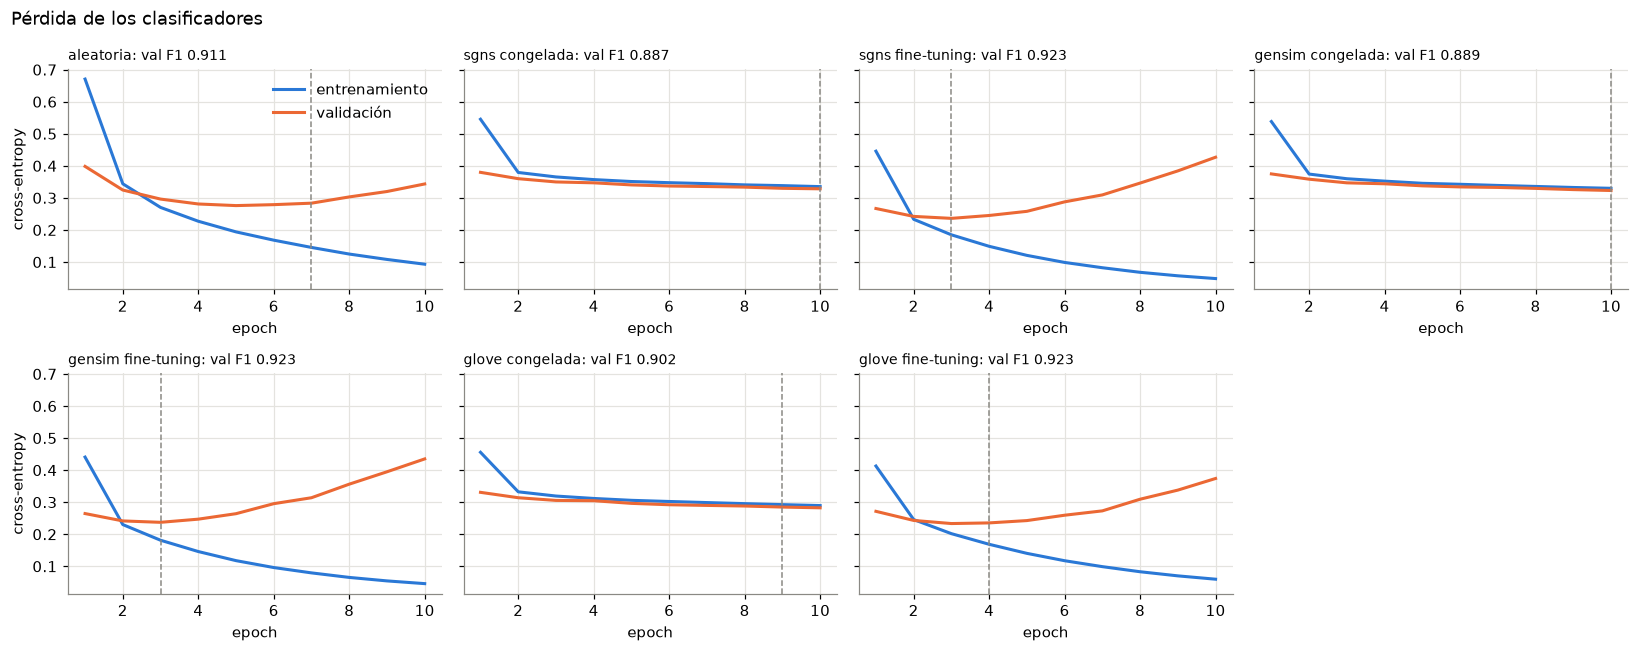

In [35]:
nombres = list(VARIANTES)
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, nombre in zip(axes.ravel(), nombres):
    h = RES_CLF[nombre]["hist"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], color=COLOR["sgns"], label="entrenamiento")
    ax.plot(ep, h["val_loss"], color=COLOR["gensim"], label="validación")
    ax.axvline(RES_CLF[nombre]["epoch"], color="#8a8984", lw=1, ls="--")
    ax.set_title(f"{nombre}: val F1 {RES_CLF[nombre]['val']['f1']:.3f}", fontsize=9, loc="left")
    ax.set_xlabel("epoch")
axes[0, 0].set_ylabel("cross-entropy")
axes[1, 0].set_ylabel("cross-entropy")
axes[0, 0].legend(frameon=False)
axes.ravel()[-1].set_visible(False)
fig.suptitle("Pérdida de los clasificadores", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("figuras/curvas_clasificacion.png")
plt.show()

Las seis variantes neuronales tienen 4,972,284 parámetros: 4,945,400 de la tabla de 49,454 palabras por 100 dimensiones y 26,884 del MLP. Al congelar la tabla solo se entrenan los 26,884 del MLP. Con el entrenamiento completo, fine-tuning es claramente mejor que congelar: 0.923 de F1 de validación para SGNS, gensim y GloVe, frente a 0.887, 0.889 y 0.902 congeladas. Las curvas muestran un patrón distinto en cada caso: con fine-tuning la pérdida de validación es mínima en la epoch 3 o 4 y luego sube por overfitting, mientras que las variantes congeladas siguen mejorando lentamente hasta la epoch 10 sin brecha entre entrenamiento y validación. La tabla aleatoria llega a 0.911 en la epoch 7 y también sobreajusta después. El baseline TF-IDF con unigramas y bigramas obtiene 0.925, el mejor F1 de validación, con 1,696,120 parámetros. Todas las variantes neuronales entrenan en unos 4 s en la GPU y TF-IDF en 31 s en CPU.

### 6.4 Evaluación final sobre test

Para cada inicialización se elige la variante con mejor F1 de validación y se evalúa una sola vez sobre el test oficial.

Mejor variante: {'aleatoria': 'aleatoria', 'sgns': 'sgns fine-tuning', 'gensim': 'gensim fine-tuning', 'glove': 'glove fine-tuning'}


TF-IDF           test acc 0.9205 | precision 0.9204 | recall 0.9205 | F1 0.9204
Aleatoria        test acc 0.9050 | precision 0.9051 | recall 0.9050 | F1 0.9049
SGNS propio      test acc 0.9157 | precision 0.9157 | recall 0.9157 | F1 0.9156
Word2Vec gensim  test acc 0.9154 | precision 0.9154 | recall 0.9154 | F1 0.9153
GloVe            test acc 0.9195 | precision 0.9200 | recall 0.9195 | F1 0.9194


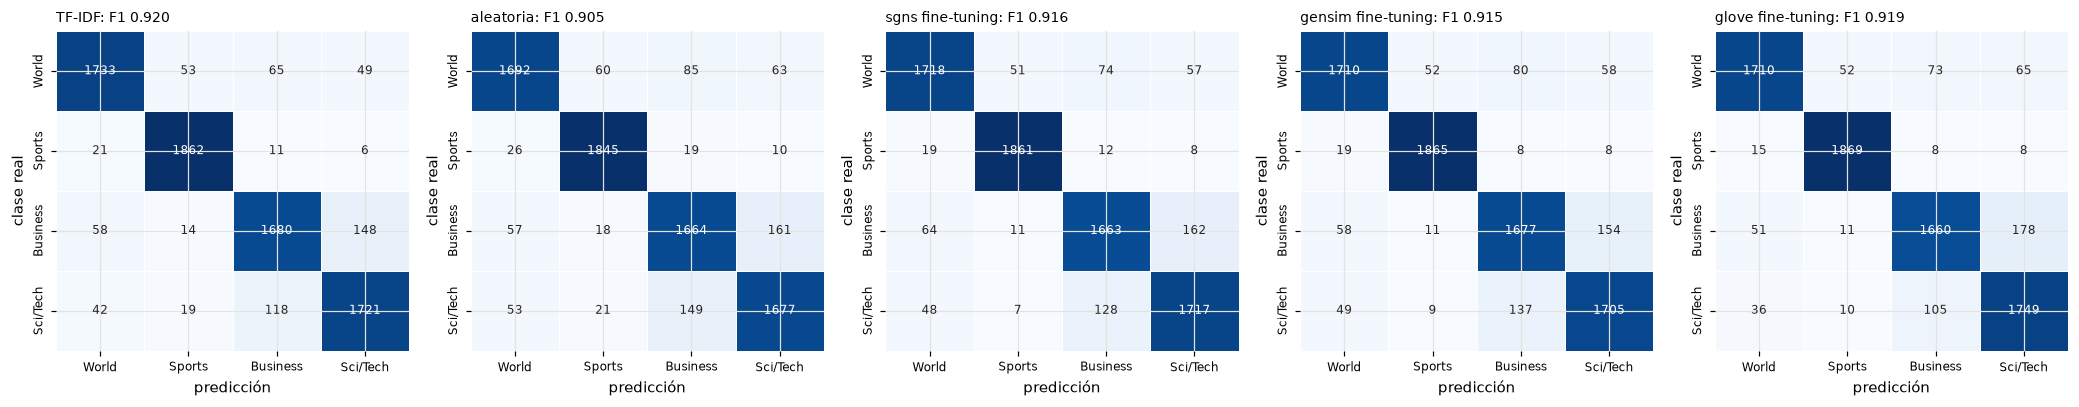

In [36]:
MEJOR_VARIANTE = {"aleatoria": "aleatoria"}
for m in ["sgns", "gensim", "glove"]:
    MEJOR_VARIANTE[m] = max([f"{m} congelada", f"{m} fine-tuning"], key=lambda n: RES_CLF[n]["val"]["f1"])
print("Mejor variante:", MEJOR_VARIANTE)

RES_TEST = {"tfidf": {**metricas(y_test, clf.predict(vect.transform(tok_test))), "pred": clf.predict(vect.transform(tok_test))}}
for init, nombre in MEJOR_VARIANTE.items():
    RES_TEST[init] = evaluar_clf(MODELOS_CLF[nombre], X_test, y_test)
for init, r in RES_TEST.items():
    print(f"{NOMBRE[init]:16s} test acc {r['accuracy']:.4f} | precision {r['precision']:.4f} | recall {r['recall']:.4f} | F1 {r['f1']:.4f}")

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, init in zip(axes, RES_TEST):
    cm = confusion_matrix(y_test, RES_TEST[init]["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=ETIQUETAS, yticklabels=ETIQUETAS,
                linewidths=0.5, linecolor="white", annot_kws={"size": 8})
    titulo = NOMBRE[init] if init == "tfidf" else MEJOR_VARIANTE[init]
    ax.set_title(f"{titulo}: F1 {RES_TEST[init]['f1']:.3f}", fontsize=9, loc="left")
    ax.set_xlabel("predicción")
    ax.set_ylabel("clase real")
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.savefig("figuras/matrices_confusion.png")
plt.show()

In [37]:
SIMLEX = {m: spearman(kv, RUTA_SIMLEX) for m, kv in MODELOS.items()}
WS353 = {m: spearman(kv, RUTA_WS353) for m, kv in MODELOS.items()}
for m in MODELOS:
    print(f"{NOMBRE[m]:16s} SimLex-999 {SIMLEX[m]:.4f} | WordSim-353 {WS353[m]:.4f}")

SGNS propio      SimLex-999 0.3089 | WordSim-353 0.6807
Word2Vec gensim  SimLex-999 0.3060 | WordSim-353 0.6815
GloVe            SimLex-999 0.2961 | WordSim-353 0.5327


En test, TF-IDF obtiene 0.920 de F1, GloVe con fine-tuning 0.919, SGNS con fine-tuning 0.916, gensim con fine-tuning 0.915 y la tabla aleatoria 0.905. Las métricas de test quedan menos de un punto por debajo de las de validación. Los cinco modelos cometen el mismo error principal, confundir Business con Sci/Tech, que suma entre 266 y 310 errores, seguido de World con Business. Sports es la clase más fácil, con más de 97 % de recall en todos.

En SimLex-999 el orden se invierte respecto a las analogías: SGNS obtiene 0.309, gensim 0.306 y GloVe 0.296. SimLex mide similitud estricta y penaliza la asociación temática, y los tres modelos quedan bajos porque aprenden asociación por contexto. Por ejemplo, good y bad son vecinos cercanos. En WordSim-353, que mide relación en general, los modelos propios también superan a GloVe, 0.681 frente a 0.533.

### 6.5 Efecto de la cantidad de datos

Se reentrenan el baseline y las variantes aleatoria, SGNS y GloVe con el 1, 5, 10, 25, 50 y 100 % del entrenamiento, muestreado de forma estratificada, y se evalúan sobre el mismo test. Con menos datos hay menos pasos por epoch, así que el número de epochs se escala como 10 entre la raíz de la fracción, con un máximo de 100, y se conserva la epoch con mejor F1 de validación.

In [38]:
FRACCIONES = [0.01, 0.05, 0.10, 0.25, 0.50, 1.0]
CURVAS = {"tfidf": [], "aleatoria": [], "sgns congelada": [], "sgns fine-tuning": [], "glove congelada": [], "glove fine-tuning": []}
for frac in FRACCIONES:
    idx_f = idx_tr if frac == 1.0 else train_test_split(idx_tr, train_size=frac, stratify=y_train_full[idx_tr], random_state=SEED)[0]
    epochs = min(100, int(round(10 / frac ** 0.5)))
    v, c = entrenar_tfidf(idx_f, C_TFIDF)
    CURVAS["tfidf"].append(metricas(y_test, c.predict(v.transform(tok_test)))["f1"])
    for nombre in list(CURVAS)[1:]:
        init, congelar = VARIANTES[nombre]
        modelo, _ = entrenar_clf(init, congelar, idx=idx_f, epochs=epochs, verbose=False)
        CURVAS[nombre].append(evaluar_clf(modelo, X_test, y_test)["f1"])
    print(f"{100 * frac:5.0f} % | {len(idx_f):6,} noticias | {epochs:3d} epochs | " +
          " | ".join(f"{n} {CURVAS[n][-1]:.4f}" for n in CURVAS))
tabla_fracciones = pd.DataFrame(CURVAS, index=[f"{100 * f:g} %" for f in FRACCIONES]).round(4)
display(tabla_fracciones)

    1 % |  1,080 noticias | 100 epochs | tfidf 0.8142 | aleatoria 0.7076 | sgns congelada 0.8582 | sgns fine-tuning 0.8621 | glove congelada 0.8703 | glove fine-tuning 0.8704


    5 % |  5,400 noticias |  45 epochs | tfidf 0.8724 | aleatoria 0.8033 | sgns congelada 0.8691 | sgns fine-tuning 0.8841 | glove congelada 0.8811 | glove fine-tuning 0.8892


   10 % | 10,800 noticias |  32 epochs | tfidf 0.8870 | aleatoria 0.8396 | sgns congelada 0.8724 | sgns fine-tuning 0.8959 | glove congelada 0.8848 | glove fine-tuning 0.8984


   25 % | 27,000 noticias |  20 epochs | tfidf 0.9026 | aleatoria 0.8750 | sgns congelada 0.8768 | sgns fine-tuning 0.9034 | glove congelada 0.8896 | glove fine-tuning 0.9062


   50 % | 54,000 noticias |  14 epochs | tfidf 0.9076 | aleatoria 0.8896 | sgns congelada 0.8798 | sgns fine-tuning 0.9110 | glove congelada 0.8934 | glove fine-tuning 0.9125


  100 % | 108,000 noticias |  10 epochs | tfidf 0.9204 | aleatoria 0.9049 | sgns congelada 0.8826 | sgns fine-tuning 0.9156 | glove congelada 0.8952 | glove fine-tuning 0.9194


,tfidf,aleatoria,sgns congelada,sgns fine-tuning,glove congelada,glove fine-tuning
1 %,0.8142,0.7076,0.8582,0.8621,0.8703,0.8704
5 %,0.8724,0.8033,0.8691,0.8841,0.8811,0.8892
10 %,0.8870,0.8396,0.8724,0.8959,0.8848,0.8984
25 %,0.9026,0.8750,0.8768,0.9034,0.8896,0.9062
50 %,0.9076,0.8896,0.8798,0.9110,0.8934,0.9125
100 %,0.9204,0.9049,0.8826,0.9156,0.8952,0.9194


Con pocos datos los embeddings preentrenados son los más útiles. Con el 1 %, 1,080 noticias, GloVe obtiene 0.870 y SGNS entre 0.858 y 0.862, frente a 0.814 de TF-IDF y 0.708 de la tabla aleatoria. Con esa cantidad congelar y hacer fine-tuning dan casi lo mismo, 0.870 frente a 0.870 en GloVe y 0.858 frente a 0.862 en SGNS, porque con tan pocos ejemplos el ajuste de la tabla aporta poco. A partir del 5 % el fine-tuning se separa de la versión congelada y su ventaja crece con los datos. TF-IDF alcanza a los preentrenados con fine-tuning cerca del 25 % y la tabla aleatoria nunca los alcanza.

## 7. Comparación de resultados

In [39]:
t_sgns = REG_MEJOR["t_total"]
hist_w2v = registro_w2v.hist
res_add = {m: resumen_analogias(RES_ANALOGIAS[(m, "add")]) for m in MODELOS}
res_mul = {m: resumen_analogias(RES_ANALOGIAS[(m, "mul")]) for m in MODELOS}
f1_test = {m: RES_TEST[m]["f1"] for m in MODELOS}

tabla_comparativa = pd.DataFrame({
    "SGNS propio": [f"{REG_MEJOR['tokens']:,}", f"{len(sgns):,}", sgns.vector_size,
                    f"{t_sgns:.0f} s, {CFG_MEJOR['epochs']} epochs", f"GPU {HARDWARE['gpu']}"],
    "Word2Vec gensim": [f"{REG_MEJOR['tokens']:,}", f"{len(w2v_kv):,}", w2v_kv.vector_size,
                        f"{sum(hist_w2v['t_epoch']):.0f} s, {CFG_MEJOR['epochs']} epochs", f"CPU {HARDWARE['cpu']}, 8 hilos"],
    "GloVe": ["6,000,000,000", f"{len(glove):,}", glove.vector_size, "85 min de conteo y 14 min por iteración a 300d, según sus autores",
              "2 Intel Xeon E5-2658 de 2.1 GHz, 32 núcleos"],
}, index=["tokens del corpus", "vocabulario", "dimensión", "tiempo de entrenamiento", "hardware"])
metricas_tabla = {}
for m, col in zip(MODELOS, tabla_comparativa.columns):
    metricas_tabla[col] = [res_add[m]["sem"], res_add[m]["sin"], res_add[m]["total"], res_mul[m]["sem"], res_mul[m]["sin"],
                           res_mul[m]["total"], WS353[m], SIMLEX[m], PARALELISMO_MEDIO[m], OOV[m], f1_test[m]]
metricas_tabla = pd.DataFrame(metricas_tabla, index=["analogías semánticas 3CosAdd", "analogías sintácticas 3CosAdd",
                                                     "analogías total 3CosAdd", "analogías semánticas 3CosMul",
                                                     "analogías sintácticas 3CosMul", "analogías total 3CosMul",
                                                     "Spearman WordSim-353", "Spearman SimLex-999",
                                                     "coseno medio entre diferencias", "% tokens OOV en AG News",
                                                     "F1 de test en AG News"]).round(4)
tabla_comparativa = pd.concat([tabla_comparativa, metricas_tabla.astype(object)])
with pd.option_context("display.max_colwidth", None):
    display(tabla_comparativa)
tabla_comparativa.to_csv("resultados/tabla_comparativa.csv", encoding="utf-8")

,SGNS propio,Word2Vec gensim,GloVe
tokens del corpus,"84,582,418","84,582,418","6,000,000,000"
vocabulario,"86,083","86,083","400,000"
dimensión,100,100,100
tiempo de entrenamiento,"645 s, 10 epochs","852 s, 10 epochs","85 min de conteo y 14 min por iteración a 300d, según sus autores"
hardware,GPU NVIDIA GeForce RTX 5070 Ti,"CPU AMD Ryzen 7 7800X3D 8-Core Processor, 8 hilos","2 Intel Xeon E5-2658 de 2.1 GHz, 32 núcleos"
analogías semánticas 3CosAdd,0.5047,0.496,0.6061
analogías sintácticas 3CosAdd,0.6012,0.595,0.6801
analogías total 3CosAdd,0.5702,0.5632,0.6563
analogías semánticas 3CosMul,0.4771,0.4746,0.5768
analogías sintácticas 3CosMul,0.5789,0.572,0.6657


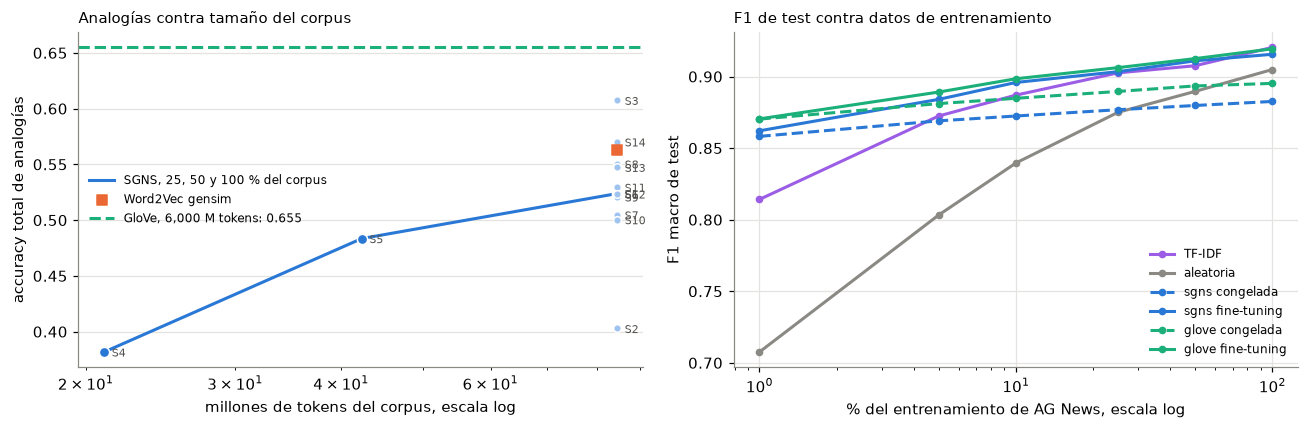

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
acc_glove = resumen_analogias(evaluar_analogias(glove))["total"]
for r in REGISTROS:
    es_corpus = r["nombre"] in ["S4", "S5", "S1"]
    ax.scatter(r["tokens"] / 1e6, r["hist"]["total"][-1], s=45 if es_corpus else 25, zorder=3,
               color=COLOR["sgns"] if es_corpus else "#9fc3ef", edgecolor="white")
    ax.annotate(r["nombre"], (r["tokens"] / 1e6, r["hist"]["total"][-1]), xytext=(5, -3), textcoords="offset points", fontsize=7, color="#52514e")
tam = [next(r for r in REGISTROS if r["nombre"] == n) for n in ["S4", "S5", "S1"]]
ax.plot([r["tokens"] / 1e6 for r in tam], [r["hist"]["total"][-1] for r in tam], color=COLOR["sgns"], label="SGNS, 25, 50 y 100 % del corpus")
ax.scatter(REG_MEJOR["tokens"] / 1e6, hist_w2v["total"][-1], marker="s", s=45, color=COLOR["gensim"], zorder=4, label="Word2Vec gensim")
ax.axhline(acc_glove, color=COLOR["glove"], ls="--", label=f"GloVe, 6,000 M tokens: {acc_glove:.3f}")
ax.set_xscale("log")
ax.set_xlabel("millones de tokens del corpus, escala log")
ax.set_ylabel("accuracy total de analogías")
ax.set_title("Analogías contra tamaño del corpus", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
estilos = {"tfidf": (COLOR["tfidf"], "-"), "aleatoria": (COLOR["aleatoria"], "-"), "sgns congelada": (COLOR["sgns"], "--"),
           "sgns fine-tuning": (COLOR["sgns"], "-"), "glove congelada": (COLOR["glove"], "--"), "glove fine-tuning": (COLOR["glove"], "-")}
for nombre, valores in CURVAS.items():
    color, ls = estilos[nombre]
    ax.plot([100 * f for f in FRACCIONES], valores, color=color, ls=ls, marker="o", ms=4, label=nombre if nombre != "tfidf" else "TF-IDF")
ax.set_xscale("log")
ax.set_xlabel("% del entrenamiento de AG News, escala log")
ax.set_ylabel("F1 macro de test")
ax.set_title("F1 de test contra datos de entrenamiento", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig("figuras/comparacion.png")
plt.show()

In [41]:
resumen = {
    "hardware": HARDWARE, "mejor": MEJOR, "cfg_mejor": CFG_MEJOR,
    "corpus": {"articulos": n_articulos, "lineas": len(lineas), "no_vacias": len(no_vacias), "parrafos": len(parrafos),
               "tokens_crudos": tokens_crudos, "tokens": N_TOKENS, "tipos": len(PALABRAS), "pares": conteo_pares,
               "zipf_pendiente": pendiente, "cobertura": {k: float(cobertura[k - 1]) for k in [10, 1000, 30000]}},
    "gensim": {"hist": hist_w2v, "t_total": t_w2v_total},
    "analogias": {f"{m} {metodo}": resumen_analogias(r) for (m, metodo), r in RES_ANALOGIAS.items()},
    "paralelismo": tabla_paralelismo.to_dict("records"), "ws353": WS353, "simlex": SIMLEX, "oov": OOV,
    "clasificacion": {n: {"val": {k: v for k, v in r["val"].items() if k != "pred"}, "params": r["params"],
                          "entrenables": r["entrenables"], "tiempo": r["tiempo"], "epoch": r["epoch"]} for n, r in RES_CLF.items()},
    "test": {m: {k: v for k, v in r.items() if k != "pred"} for m, r in RES_TEST.items()},
    "mejor_variante": MEJOR_VARIANTE, "fracciones": CURVAS,
}
with open("resultados/resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=1, default=float)
print("Hardware utilizado:", HARDWARE["gpu"], "|", HARDWARE["cpu"])

Hardware utilizado: NVIDIA GeForce RTX 5070 Ti | AMD Ryzen 7 7800X3D 8-Core Processor


La implementación propia y gensim son prácticamente equivalentes en todas las métricas, con diferencias menores a un punto. GloVe es mejor en analogías, 65.6 % frente a 57.0 %, y en paralelismo, 0.405 frente a 0.280, gracias a un corpus 71 veces más grande. Los modelos propios son mejores en WordSim-353 y SimLex-999. En AG News GloVe tiene cuatro veces menos tokens fuera del vocabulario, 0.92 % frente a 3.77 %, y obtiene un F1 de test 0.4 puntos mayor. En la gráfica de la izquierda cada duplicación del corpus mejora menos: 10.2 puntos de 25 % a 50 % y 4.0 de 50 % a 100 %. En la de la derecha las curvas preentrenadas con fine-tuning quedan arriba en todas las fracciones y las congeladas se aplanan a partir del 10 %.

## 8.

### Aritmética vectorial

Sí se cumple como aproximación. SGNS acierta el 57.0 % de las analogías del vocabulario compartido y 16 de las 18 analogías propias. Funciona mejor en relaciones regulares y frecuentes, como gentilicios con 88.2 %, capitales comunes con 72.7 %, pasado con 72.3 % y comparativos con 69.8 %, y falla en monedas, opuestos y adjetivo a adverbio.

### ¿Es el ≈ una igualdad?

No. Sin excluir las palabras de la consulta, king − man + woman tiene como vecino más cercano a king y queen queda segunda, con similitud 0.738. En 10 de las 18 analogías propias la palabra más cercana al resultado es una de la consulta. Además, los vectores diferencia de una misma relación tienen coseno promedio de 0.28 en SGNS y 0.32 para el género, lejos del 1 que tendrían si fueran paralelos.

### Distancia con GloVe

El mejor modelo quedó 8.6 puntos debajo de GloVe en analogías, 57.0 % frente a 65.6 %, y la diferencia se concentra en las semánticas, 50.5 % frente a 60.6 %.

### SGNS propio frente a gensim

Se comportan casi igual: 57.0 % frente a 56.3 % en analogías, 0.681 frente a 0.682 en WordSim-353 y 0.916 frente a 0.915 de F1 en AG News, con vecinos muy parecidos. Las diferencias pequeñas se deben a la forma de actualizar: gensim actualiza par por par en varios hilos sin bloqueo, mientras que la versión propia suma los gradientes de 32,768 pares y recorta el de las filas muy frecuentes.

### Dimensión, ventana y negativos

La dimensión fue el factor más importante: de 50 a 300 el accuracy subió de 40.3 % a 60.7 % y el tiempo por epoch se multiplicó por 2.5. Más negativos subieron el accuracy de 52.4 % a 55.1 %, sobre todo en semánticas, a cambio del doble de tiempo.

### Clasificación de AG News

Los embeddings preentrenados con fine-tuning superaron a la tabla aleatoria, 0.916 y 0.919 frente a 0.905 de F1 en test, pero no al baseline TF-IDF, que obtuvo 0.920 porque usa bigramas y 424 mil rasgos sobre un problema donde las palabras clave bastan.
